# Supervised Learning - Foundations Project: ReCell

## Problem Statement

### Business Context

Buying and selling used phones and tablets used to be something that happened on a handful of online marketplace sites. But the used and refurbished device market has grown considerably over the past decade, and a new IDC (International Data Corporation) forecast predicts that the used phone market would be worth \\$52.7bn by 2023 with a compound annual growth rate (CAGR) of 13.6% from 2018 to 2023. This growth can be attributed to an uptick in demand for used phones and tablets that offer considerable savings compared with new models.

Refurbished and used devices continue to provide cost-effective alternatives to both consumers and businesses that are looking to save money when purchasing one. There are plenty of other benefits associated with the used device market. Used and refurbished devices can be sold with warranties and can also be insured with proof of purchase. Third-party vendors/platforms, such as Verizon, Amazon, etc., provide attractive offers to customers for refurbished devices. Maximizing the longevity of devices through second-hand trade also reduces their environmental impact and helps in recycling and reducing waste. The impact of the COVID-19 outbreak may further boost this segment as consumers cut back on discretionary spending and buy phones and tablets only for immediate needs.


### Objective

The rising potential of this comparatively under-the-radar market fuels the need for an ML-based solution to develop a dynamic pricing strategy for used and refurbished devices. ReCell, a startup aiming to tap the potential in this market, has hired you as a data scientist. They want you to analyze the data provided and build a linear regression model to predict the price of a used phone/tablet and identify factors that significantly influence it.


### Data Description

The data contains the different attributes of used/refurbished phones and tablets. The data was collected in the year 2021. The detailed data dictionary is given below.


- brand_name: Name of manufacturing brand
- os: OS on which the device runs
- screen_size: Size of the screen in cm
- 4g: Whether 4G is available or not
- 5g: Whether 5G is available or not
- main_camera_mp: Resolution of the rear camera in megapixels
- selfie_camera_mp: Resolution of the front camera in megapixels
- int_memory: Amount of internal memory (ROM) in GB
- ram: Amount of RAM in GB
- battery: Energy capacity of the device battery in mAh
- weight: Weight of the device in grams
- release_year: Year when the device model was released
- days_used: Number of days the used/refurbished device has been used
- normalized_new_price: Normalized price of a new device of the same model in euros
- normalized_used_price: Normalized price of the used/refurbished device in euros

## Importing necessary libraries

In [ ]:
# Libraries for reading and handling the data
import numpy as np
import pandas as pd

#Libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

#Import libraries for splitting train and test data
from sklearn.model_selection import train_test_split

#Import to build linear regression model
from sklearn.linear_model import LinearRegression

#Import to check model performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Import to build linear regression model using statsmodels
import statsmodels.api as sm

#Import to compute Variance Inflation Factors
from statsmodels.stats.outliers_influence import variance_inflation_factor

## Loading the dataset

In [ ]:
df = pd.read_csv("data/used_device_data.csv")

Mounted at /content/drive


## Data Overview

### Observations


In [ ]:
#Check the first 5 rows of the Data
df.head()

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
0,Honor,Android,14.50,yes,no,13.0,5.0,64.0,3.0,3020.0,146.0,2020,127,4.307572,4.715100
1,Honor,Android,17.30,yes,yes,13.0,16.0,128.0,8.0,4300.0,213.0,2020,325,5.162097,5.519018
2,Honor,Android,16.69,yes,yes,13.0,8.0,128.0,8.0,4200.0,213.0,2020,162,5.111084,5.884631
3,Honor,Android,25.50,yes,yes,13.0,8.0,64.0,6.0,7250.0,480.0,2020,345,5.135387,5.630961
4,Honor,Android,15.32,yes,no,13.0,8.0,64.0,3.0,5000.0,185.0,2020,293,4.389995,4.947837


In [ ]:
#Check the last 5 rows of the data
df.tail()

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
3449,Asus,Android,15.34,yes,no,NaN,8.0,64.0,6.0,5000.0,190.0,2019,232,4.492337,6.483872
3450,Asus,Android,15.24,yes,no,13.0,8.0,128.0,8.0,4000.0,200.0,2018,541,5.037732,6.251538
3451,Alcatel,Android,15.80,yes,no,13.0,5.0,32.0,3.0,4000.0,165.0,2020,201,4.357350,4.528829
3452,Alcatel,Android,15.80,yes,no,13.0,5.0,32.0,2.0,4000.0,160.0,2020,149,4.349762,4.624188
3453,Alcatel,Android,12.83,yes,no,13.0,5.0,16.0,2.0,4000.0,168.0,2020,176,4.132122,4.279994


- The dataset contains information about device specifications
- We can already see there are some missing values

In [ ]:
#Check the shape of the data set
df.shape

(3454, 15)

- There are 3454 Rows and 15 Columns displaying device attributes in the Data Set

In [ ]:
#Check the data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3454 entries, 0 to 3453
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   brand_name             3454 non-null   object 
 1   os                     3454 non-null   object 
 2   screen_size            3454 non-null   float64
 3   4g                     3454 non-null   object 
 4   5g                     3454 non-null   object 
 5   main_camera_mp         3275 non-null   float64
 6   selfie_camera_mp       3452 non-null   float64
 7   int_memory             3450 non-null   float64
 8   ram                    3450 non-null   float64
 9   battery                3448 non-null   float64
 10  weight                 3447 non-null   float64
 11  release_year           3454 non-null   int64  
 12  days_used              3454 non-null   int64  
 13  normalized_used_price  3454 non-null   float64
 14  normalized_new_price   3454 non-null   float64
dtypes: f

- There are 9 Columns with the 'float' as the data type (screen_size, main_camera_mp, selfie_camera_np, int_memory, ram, battery, weight, normalized_used_price, normalized_new_price)
- There are 2 Columns with 'integer' as the data type (release_year and days_used)
- There are 4 Columns with 'object' as the data type (brand_name, os, 4g, 5g)
- We can see that there is some missing data in 6 columns


In [ ]:
#Check statistical summary of all numeric columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
screen_size,3454.0,13.713115,3.805280,5.080000,12.700000,12.830000,15.340000,30.710000
main_camera_mp,3275.0,9.460208,4.815461,0.080000,5.000000,8.000000,13.000000,48.000000
selfie_camera_mp,3452.0,6.554229,6.970372,0.000000,2.000000,5.000000,8.000000,32.000000
int_memory,3450.0,54.573099,84.972371,0.010000,16.000000,32.000000,64.000000,1024.000000
ram,3450.0,4.036122,1.365105,0.020000,4.000000,4.000000,4.000000,12.000000
battery,3448.0,3133.402697,1299.682844,500.000000,2100.000000,3000.000000,4000.000000,9720.000000
weight,3447.0,182.751871,88.413228,69.000000,142.000000,160.000000,185.000000,855.000000
release_year,3454.0,2015.965258,2.298455,2013.000000,2014.000000,2015.500000,2018.000000,2020.000000
days_used,3454.0,674.869716,248.580166,91.000000,533.500000,690.500000,868.750000,1094.000000
normalized_used_price,3454.0,4.364712,0.588914,1.536867,4.033931,4.405133,4.755700,6.619433


- we can see the normalized used price which we will exploring later has a range from 1.53 to 6.62 Euros with what seems to be a fairly normal distribution evidenced by similar median and mean
- We can say a high number of the devices have 4GB of RAM evidenced by the IQR having a range of 0


In [ ]:
#Check statistical summary of all non-numeric columns
df.describe(include='object').T

,count,unique,top,freq
brand_name,3454,34,Others,502
os,3454,4,Android,3214
4g,3454,2,yes,2335
5g,3454,2,no,3302


- We have 33 different brands of devices with a 34th column representing other brands not specifically named. The 'Others' category is the largest grouping of devices with 502 devices in this category.

- There are 4 types of operating systems in the data set, with android being the most common

- We can see that most devices have 4g capabiities and not many devices have 5g capabilities.

- We can also see that 4g and 5g are not exclusive, where devices can be enabled with both.

### Sanity checks

In [ ]:
#Check for duplicates in the data
df.duplicated().sum()

0

- There are no duplicates in the data

In [ ]:
#Check for missing values
df.isnull().sum()

brand_name                 0
os                         0
screen_size                0
4g                         0
5g                         0
main_camera_mp           179
selfie_camera_mp           2
int_memory                 4
ram                        4
battery                    6
weight                     7
release_year               0
days_used                  0
normalized_used_price      0
normalized_new_price       0
dtype: int64

There are a six columns with missing data
- main_camera_mp has 179 missing values
- selfie_camera_mp has 2 missing values
- int_memory has 4 missing values
- ram has 4 missing vlaues
- battery has 6 missing values
- weight has 7 missing values

In [ ]:
#create a copy of the data for data manipulation and to preserve the original data set
df1 = df.copy()

## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Questions**:
1. What does the distribution of normalized used device prices look like?
2. What percentage of the used device market is dominated by Android devices?
3. The amount of RAM is important for the smooth functioning of a device. How does the amount of RAM vary with the brand?
4. A large battery often increases a device's weight, making it feel uncomfortable in the hands. How does the weight vary for phones and tablets offering large batteries (more than 4500 mAh)?
5. Bigger screens are desirable for entertainment purposes as they offer a better viewing experience. How many phones and tablets are available across different brands with a screen size larger than 6 inches?
6. A lot of devices nowadays offer great selfie cameras, allowing us to capture our favorite moments with loved ones. What is the distribution of devices offering greater than 8MP selfie cameras across brands?
7. Which attributes are highly correlated with the normalized price of a used device?

###Univariate Analysis

####Normalized Used Price

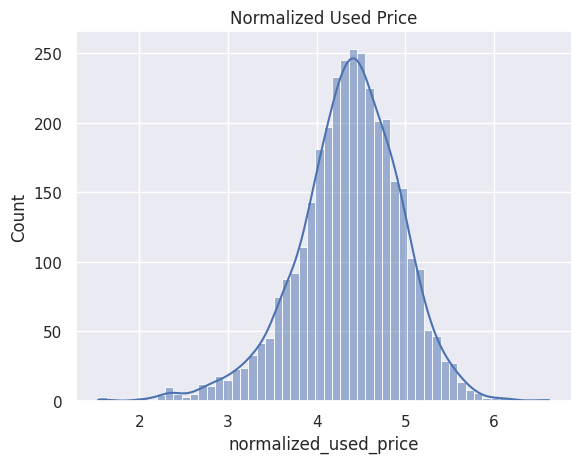

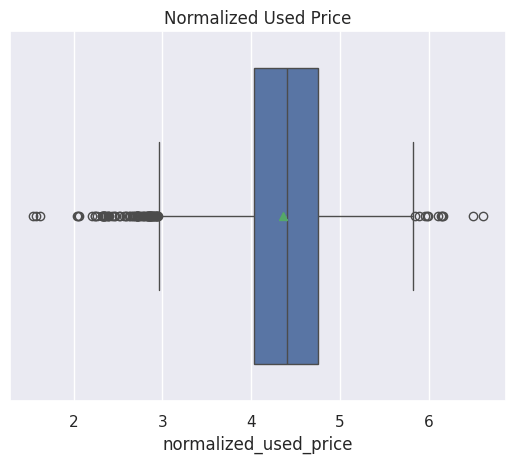

In [ ]:
#Visualize the distribution of normalized used device prices

sns.histplot(data=df1, x= 'normalized_used_price', kde=True)
plt.title('Normalized Used Price')
plt.show()

sns.boxplot(data=df1, x= 'normalized_used_price', showmeans=True)
plt.title('Normalized Used Price')
plt.show()

- The distribution of normalized_used_price seems to follow a normal distribution since it appears to be a bell shaped curve in the histogram and in the box plot the mean and median are relatively close to eachother.



####Normalized New Price

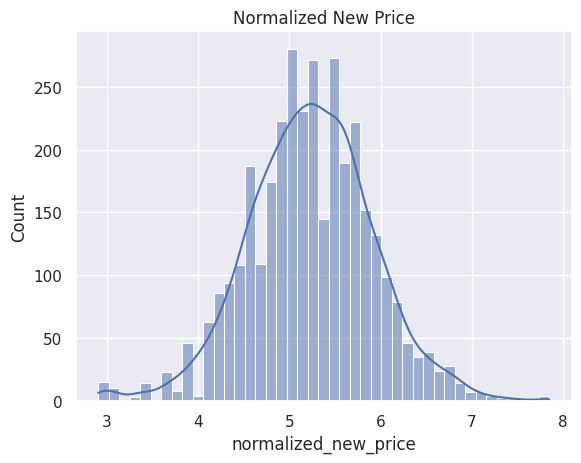

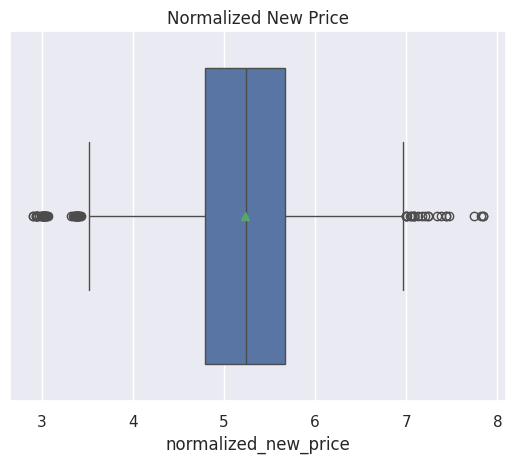

In [ ]:
#Visualize the distribution of normalized new device prices
sns.histplot(data=df1, x= 'normalized_new_price', kde=True)
plt.title('Normalized New Price')
plt.show()
sns.boxplot(data=df1, x= 'normalized_new_price', showmeans=True)
plt.title('Normalized New Price')
plt.show()

- The distribution of normalized_new_price seems to follow a normal distribution since it appears to be a bell shaped curve in the histogram and in the box plot the mean and median are relatively close to eachother.

#### Screen Size

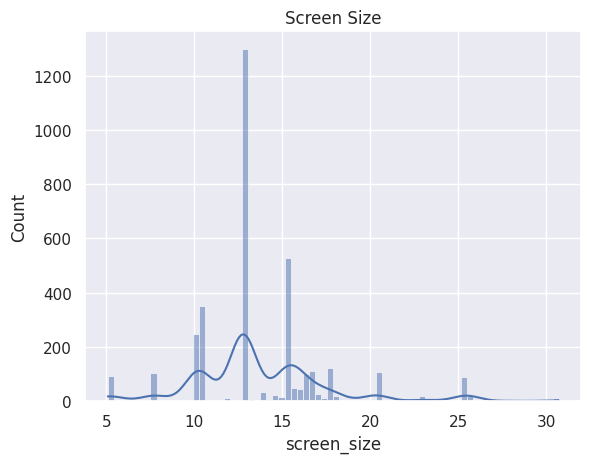

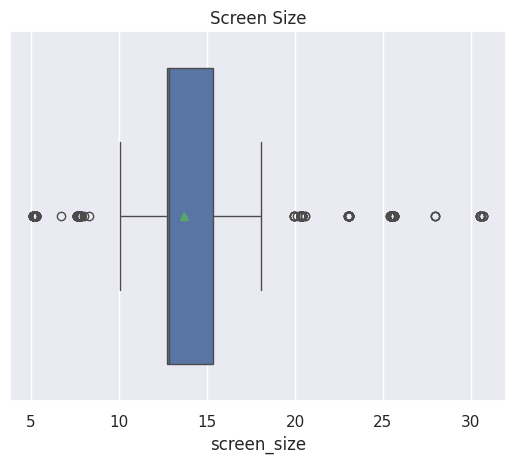

In [ ]:
#Visualize the distribution of screen size
sns.histplot(data=df1, x= 'screen_size', kde=True)
plt.title('Screen Size')
plt.show()
sns.boxplot(data=df1, x= 'screen_size', showmeans=True)
plt.title('Screen Size')
plt.show()

In [ ]:
df1['screen_size'].mode()

0    12.7
Name: screen_size, dtype: float64

- Screen size is not a normal distribution with it being heavily skewed to the right and having multi-modal qualities as well.

- The most common screen size among devices is 12.7 cm

- The distribution is also skewed keavily to the right with the median being smaller size than the mean

####Main Camera Mega Pixels

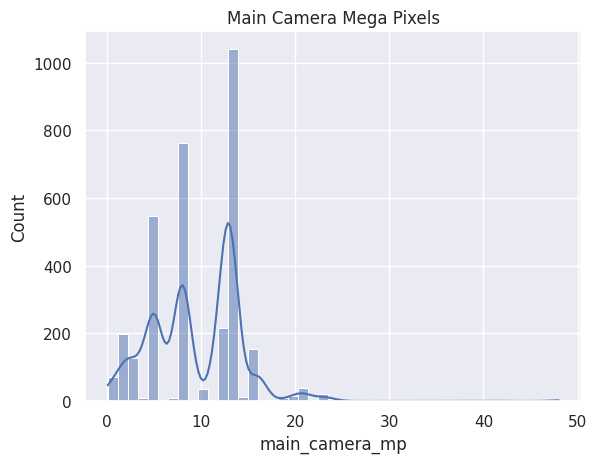

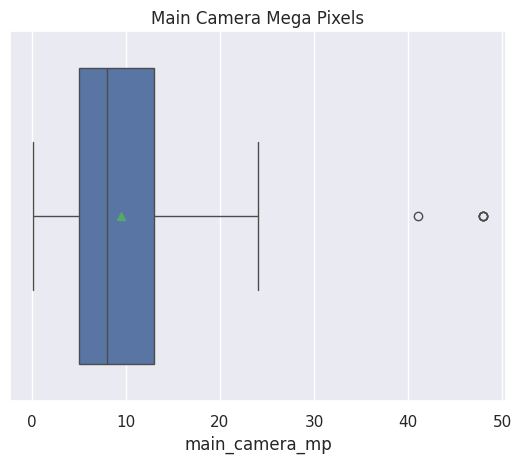

In [ ]:
#Visualize the distribution of main camera mega pixels
sns.histplot(data=df1, x= 'main_camera_mp', kde=True)
plt.title('Main Camera Mega Pixels')
plt.show()
sns.boxplot(data=df1, x= 'main_camera_mp', showmeans=True)
plt.title('Main Camera Mega Pixels')
plt.show()

- The distribution of main camera megapixels is multi-modal, with a right skew on the data.

- There are a few outliers in this data, which will need to be looked at due to their scarcity and distance from the upper tail

####Selfie Camera Mega Pixels

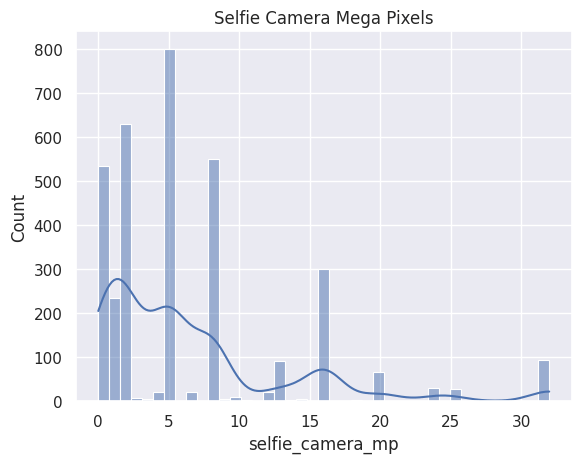

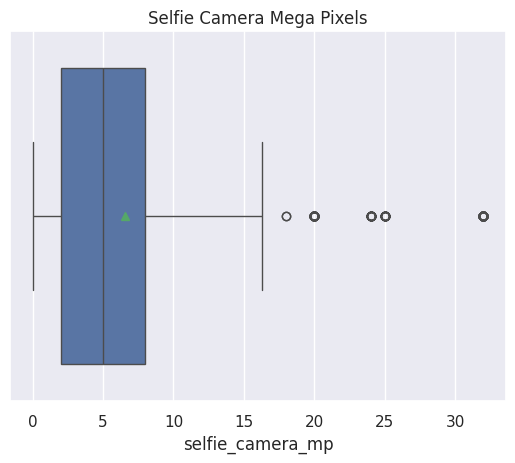

In [ ]:
#Visualize the distribution of selfie camera mega pixels
sns.histplot(data=df1, x= 'selfie_camera_mp', kde=True)
plt.title('Selfie Camera Mega Pixels')
plt.show()
sns.boxplot(data=df1, x= 'selfie_camera_mp', showmeans=True)
plt.title('Selfie Camera Mega Pixels')
plt.show()

- Selfie Camera megapixels follows a similar distribution being right skewed with outliers above the upper tail
- The outliers for this column will likely need to be explored as well

####Internal Memory

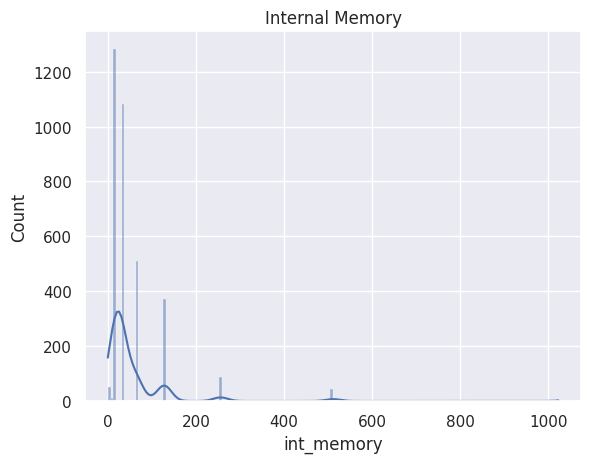

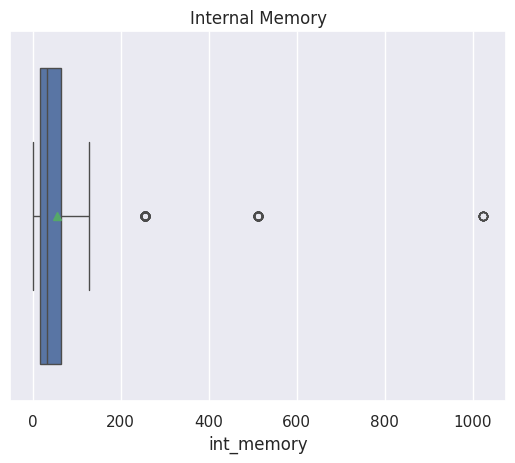

In [ ]:
#Visualize the distribution of internal memory
sns.histplot(data=df1, x= 'int_memory', kde=True)
plt.title('Internal Memory')
plt.show()
sns.boxplot(data=df1, x= 'int_memory', showmeans=True)
plt.title('Internal Memory')
plt.show()

- Internal memory has a relatively small range and is heavily skewed to the right

- The outliers in this column will also require some exploration

- Most devices have an internal memory below 200 GB

#### RAM

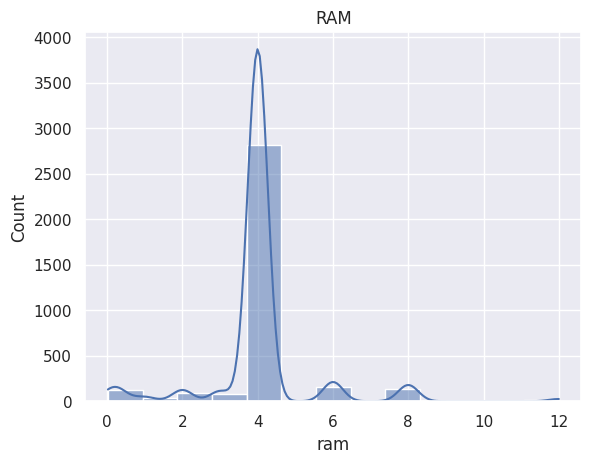

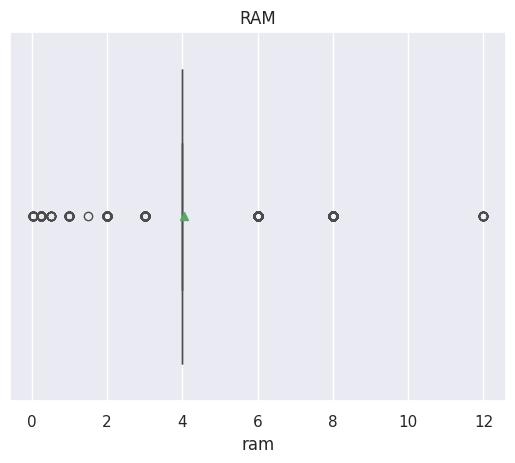

In [ ]:
#Visualize the distribution of ram
sns.histplot(data=df1, x= 'ram', kde=True)
plt.title('RAM')
plt.show()
sns.boxplot(data=df1, x= 'ram', showmeans=True)
plt.title('RAM')
plt.show()

- RAM seems to be somehwat normally distributed, with almost all devices having 4 GB of RAM.

- Almost all RAM sizes not equal to 4 are considered outliers in the distribution



#### Battery

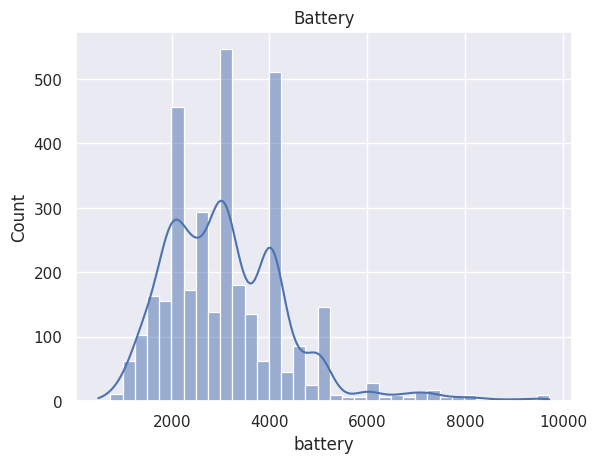

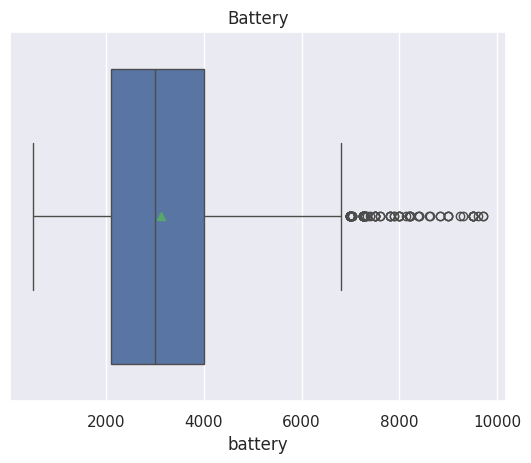

In [ ]:
#Visualize the distribution of Battery
sns.histplot(data=df1, x= 'battery', kde=True)
plt.title('Battery')
plt.show()
sns.boxplot(data=df1, x= 'battery', showmeans=True)
plt.title('Battery')
plt.show()

- The distribution of battery capacity is skewed to the right, with the IQR being inbetween 2000 and 4000 mAh

####Weight

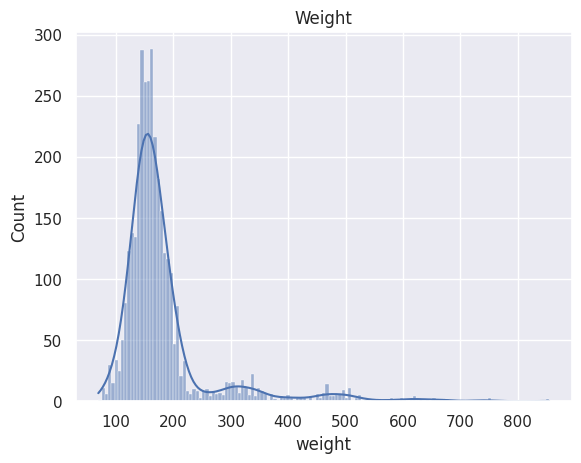

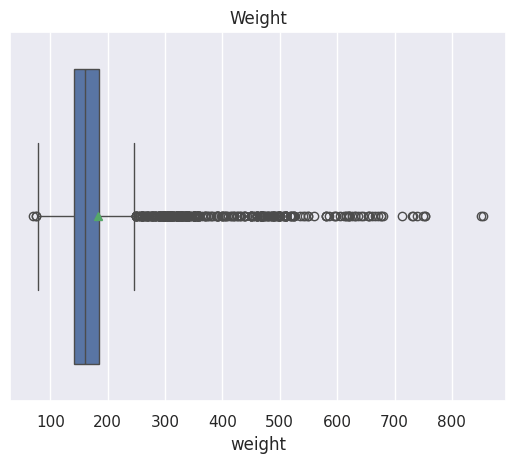

In [ ]:
#Visualize the distribution of weight
sns.histplot(data=df1, x= 'weight', kde=True)
plt.title('Weight')
plt.show()
sns.boxplot(data=df1, x= 'weight', showmeans=True)
plt.title('Weight')
plt.show()

- Weight follows a bell shaped curve with a long tail on the upper end leading to a right skew

- Most devices fall under 300g in weight

- The largest devices are over 800g

#### Days Used

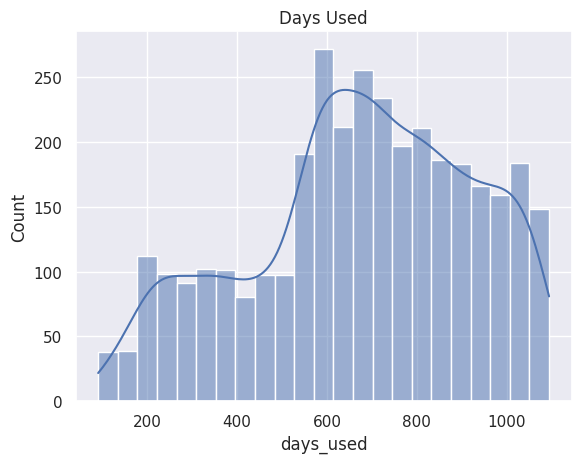

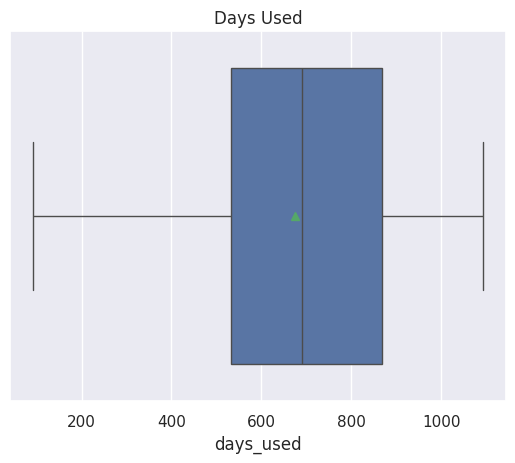

In [ ]:
#Visualize the distribution of days used
sns.histplot(data=df1, x= 'days_used', kde=True)
plt.title('Days Used')
plt.show()
sns.boxplot(data=df1, x= 'days_used', showmeans=True)
plt.title('Days Used')
plt.show()

- The distribution of days used is left skewed with most of the devices being used for longer than year.

- The mean and median are relatively close in value being at just over two years

####Brand Name

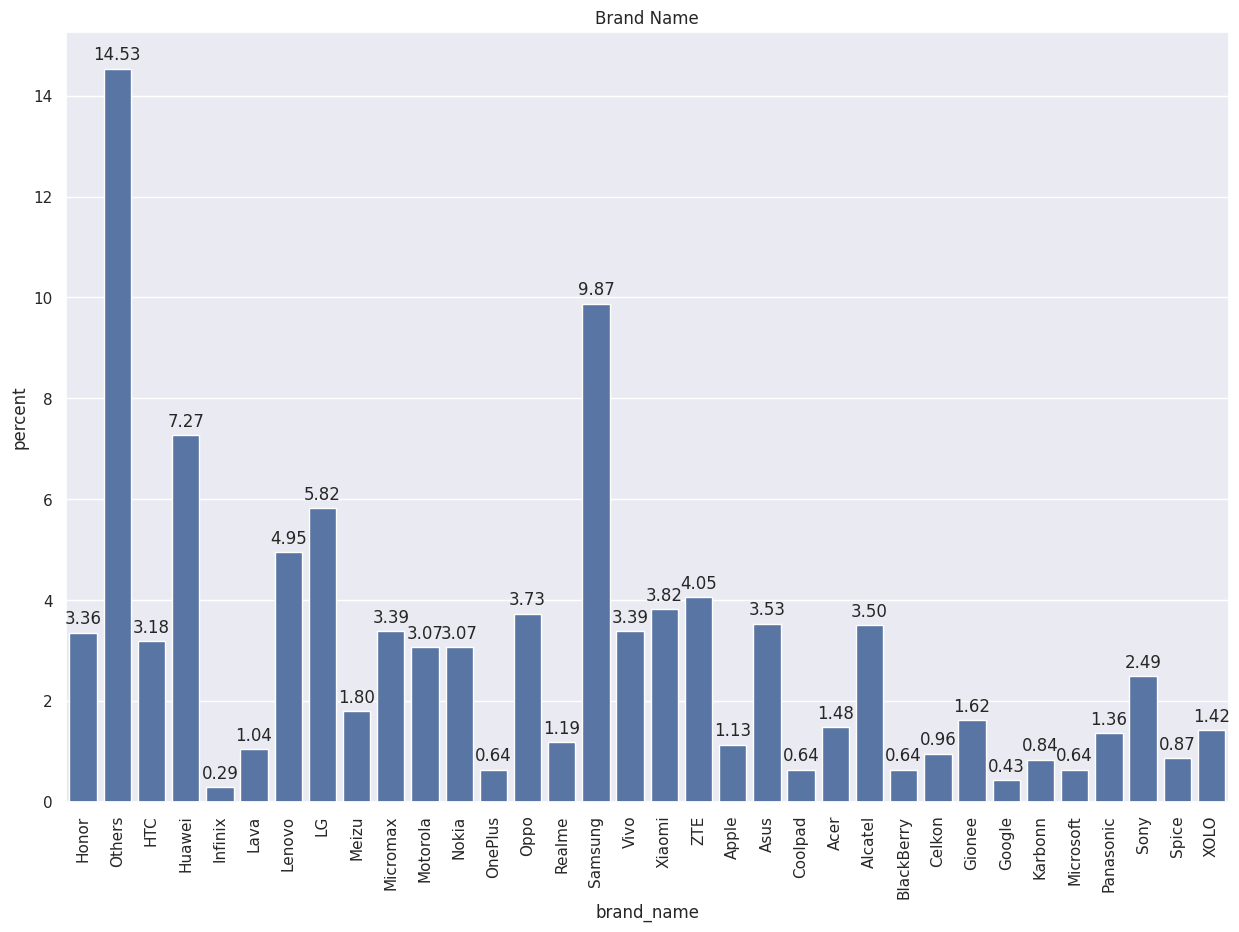

In [ ]:
# Visualize the distribution of brand name
plt.figure(figsize= (15,10))
brand_name_plot = sns.countplot(data=df1, x='brand_name', stat='percent')
plt.title('Brand Name')
plt.xticks(rotation=90)
for p in brand_name_plot.patches:
  brand_name_plot.annotate(format(p.get_height(), '.2f'), (p.get_x() + p.get_width() / 2., p.get_height()),  ha = 'center', va = 'center', xytext = (0, 10), textcoords = 'offset points')
plt.show()

- 'Others' is the largest category for brand name making up 14.5% of the devices

- The signle brand with the most devices is Samsung followed by Huawei and LG with 9.87%, 7.27% and 5.82% respectively

- Infinix and Google make up the smallest portion of the dataset with .29% and
 .43%, respectively

####Operating System

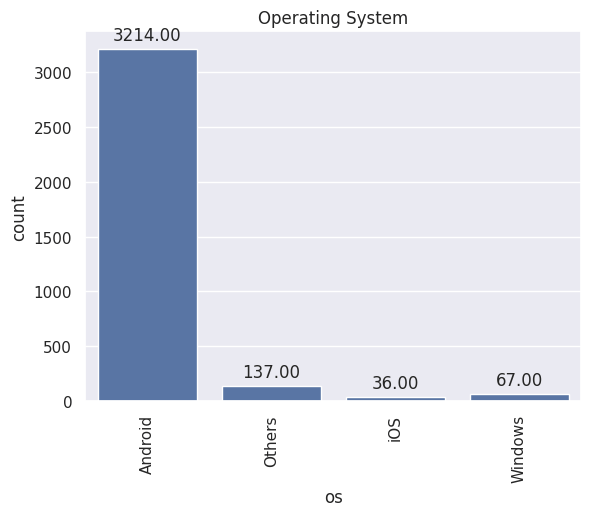

In [ ]:
#visualize OS
os_plot = sns.countplot(data=df1, x='os')
plt.title('Operating System')
plt.xticks(rotation=90)
for p in os_plot.patches:
  os_plot.annotate(format(p.get_height(), '.2f'), (p.get_x() + p.get_width() / 2., p.get_height()),  ha = 'center', va = 'center', xytext = (0, 10), textcoords = 'offset points')
plt.show()

- 3214 devices use the Android operating systems

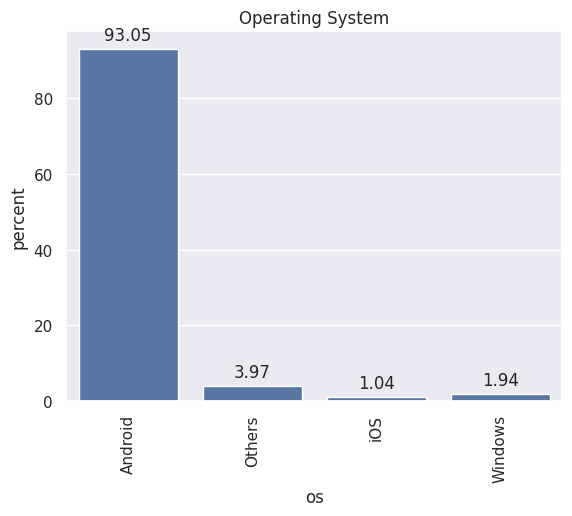

In [ ]:
#visualize the percentage of each OS
os_plot = sns.countplot(data=df1, x='os', stat='percent')
plt.title('Operating System')
plt.xticks(rotation=90)
for p in os_plot.patches:
  os_plot.annotate(format(p.get_height(), '.2f'), (p.get_x() + p.get_width() / 2., p.get_height()),  ha = 'center', va = 'center', xytext = (0, 10), textcoords = 'offset points')
plt.show()


- The android operating system makes up 93.05% of the devices in the dataset

- iOS makes up the smallest portion within the dataset at just over 1% (1.04%)

####4G

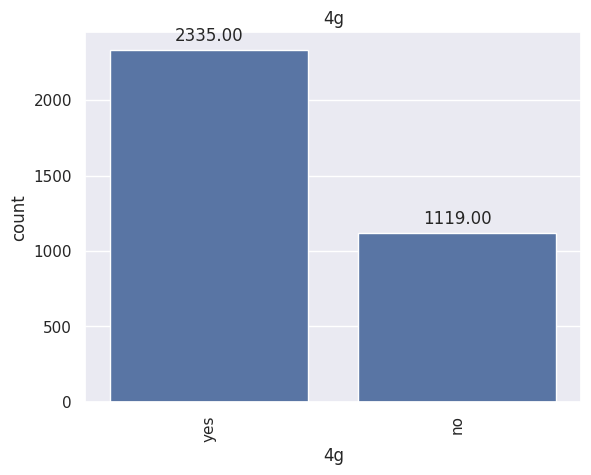

In [ ]:
#visualize 4g
fourg_plot = sns.countplot(data=df1, x='4g')
plt.title('4g')
plt.xticks(rotation=90)
for p in fourg_plot.patches:
  fourg_plot.annotate(format(p.get_height(), '.2f'), (p.get_x() + p.get_width() / 2., p.get_height()),  ha = 'center', va = 'center', xytext = (0, 10), textcoords = 'offset points')
plt.show()

- 2335 devices have 4g capability while 1119 devices do not have 4g capability

####5G

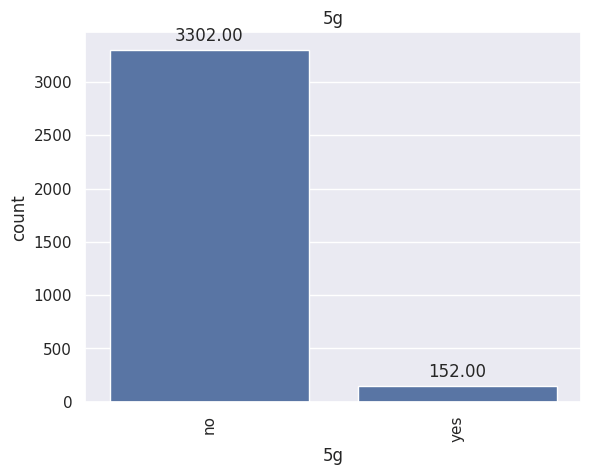

In [ ]:
#visualize 5g
fiveg_plot = sns.countplot(data=df1, x='5g')
plt.title('5g')
plt.xticks(rotation=90)
for p in fiveg_plot.patches:
  fiveg_plot.annotate(format(p.get_height(), '.2f'), (p.get_x() + p.get_width() / 2., p.get_height()),  ha = 'center', va = 'center', xytext = (0, 10), textcoords = 'offset points')
plt.show()

- 152 devices have 5g capability while 3302 devices do not have 5g capability

- When comparing this to the distribution of 4G devices we can see there are devies with both 4G and 5G capabilities enabled.

####Release Year

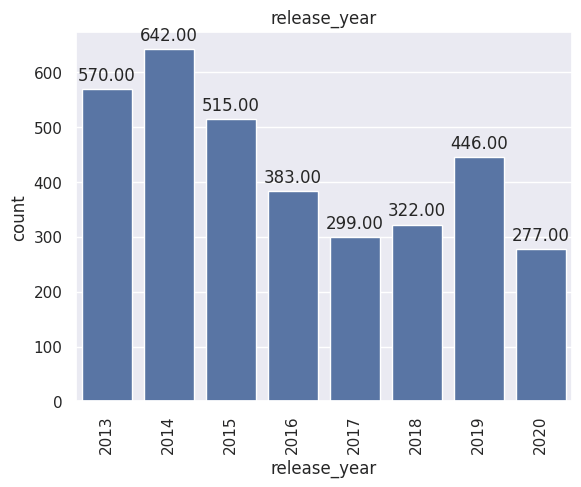

In [ ]:
#visualize release year
release_year_plot = sns.countplot(data=df1, x='release_year')
plt.title('release_year')
plt.xticks(rotation=90)
for p in release_year_plot.patches:
  release_year_plot.annotate(format(p.get_height(), '.2f'), (p.get_x() + p.get_width() / 2., p.get_height()),  ha = 'center', va = 'center', xytext = (0, 10), textcoords = 'offset points')
plt.show()

- The visualization shows that the most common release year is 2014
- The least common release year is 2020
- The device range in release year with the earliest release being in 2013 and the latest release being in 2020
- The distribution is right skewed with most of the devices being released before 2017

Obseravations and Insights
- After completing a univariate analysis, we can see that nearly all the numeric independent variables are skewed to the right with many having outliers above the upper tail.

- We can assume that for future treatments and imputations we will most likely be utlizing median over mean due to outlier and skew sensitivity properties having a larger influence on the mean.



###Bivariate Analysis

####Correlation of Numeric Variables

In [ ]:
#corrrelation check on numeric variables
n_cols = df1.select_dtypes(include = np.number).columns.to_list()
n_cols

['screen_size',
 'main_camera_mp',
 'selfie_camera_mp',
 'int_memory',
 'ram',
 'battery',
 'weight',
 'release_year',
 'days_used',
 'normalized_used_price',
 'normalized_new_price']

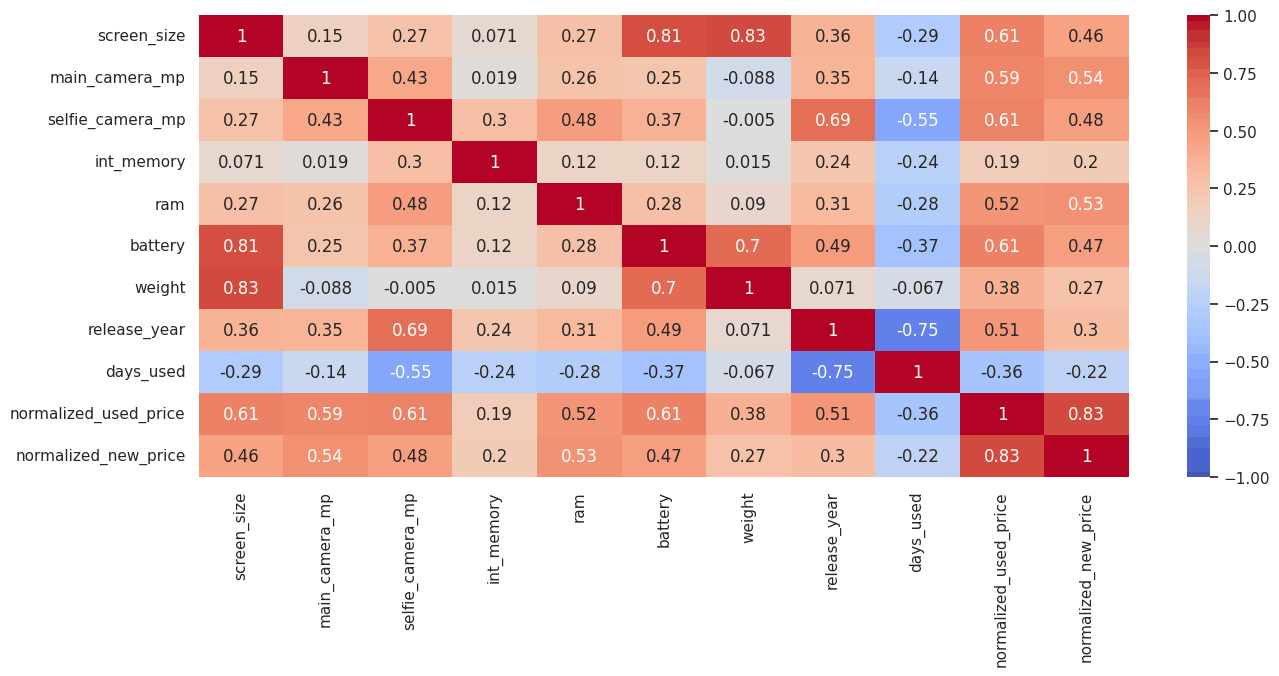

In [ ]:
#visualize the correlations of the numeric columns
plt.figure(figsize=(15,6))
sns.heatmap(df1[n_cols].corr(), annot=True, vmin=-1, vmax=1, cmap="coolwarm")
plt.show()

- The highest observed correlation is between screen size paired with both battery size and weight, which makes perfect sense, since the screen the larger the phone and in turn more available space for a larger battery.

- Release year and Selfie Camera MP are also correlated which could likely be explained by advances in camera technology.

- Battery and weight are relatively correlated as well, however, I'm surprised to see that the correlation is less than with screen size.

- The variables with the highest correlation with noramlized used price are: normalized new price (.83), battery (.61), selfie camera mp (.61), screen size (.61), main camera mp (.59), RAM (.52) and release year (.51) all of which have positive correlations greater than .5

- Days used is the only variable negatively correlated with normalized used price (-.36)

####RAM vs Brand

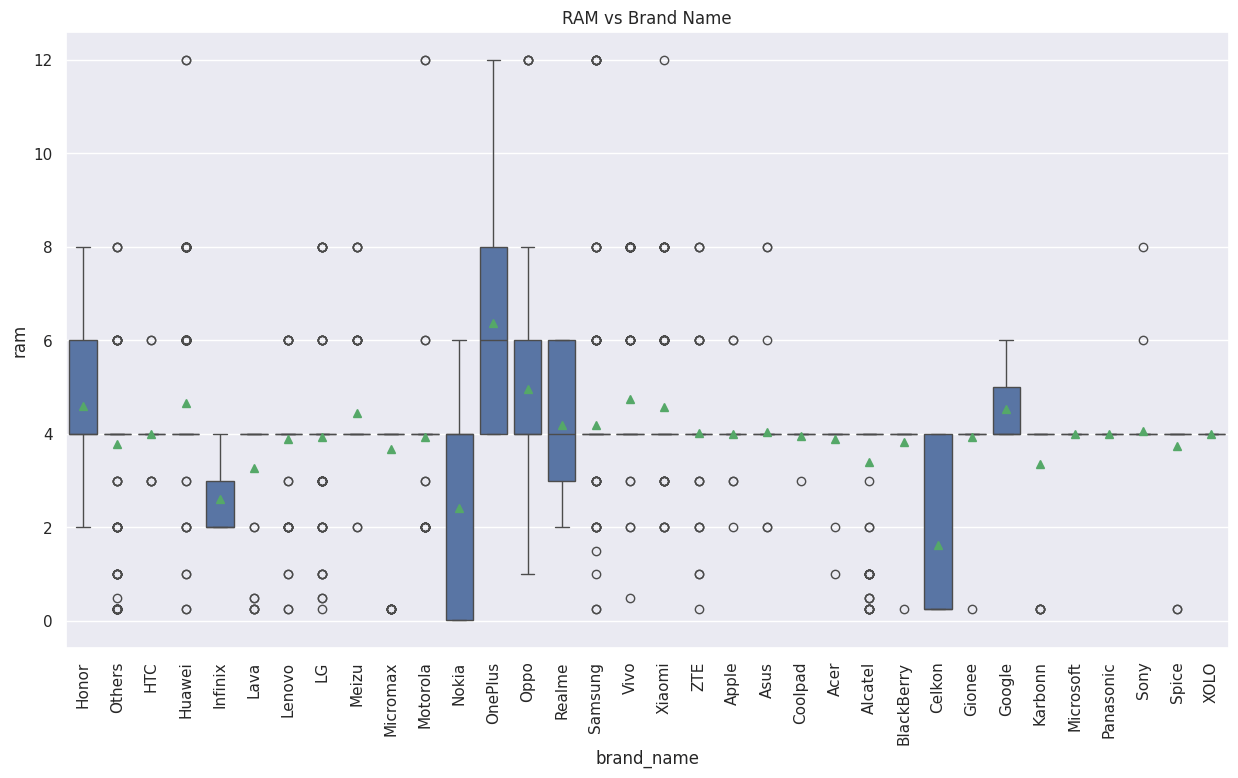

In [ ]:
#Visualize the relationship between RAM and Brand name
plt.figure(figsize=(15,8))
sns.boxplot(data=df1, x='brand_name', y='ram', showmeans=True)
plt.xticks(rotation=90)
plt.title('RAM vs Brand Name')
plt.show()

- The average RAM across each Brand is generally at 4GB
- One plus has the highest average and median RAM with the Median being 6GB and the Average being just above 6GB
- The max RAM is 12 GB with 6 different brands having a device with this amount of RAM.

####Large Battery vs Weight

In [ ]:
#create a new variable for a data set with only large batteries over 4500mAh
large_battery= df1[df1['battery']>4500]
large_battery.shape

(341, 15)

- There are 341 devices with a large a battery

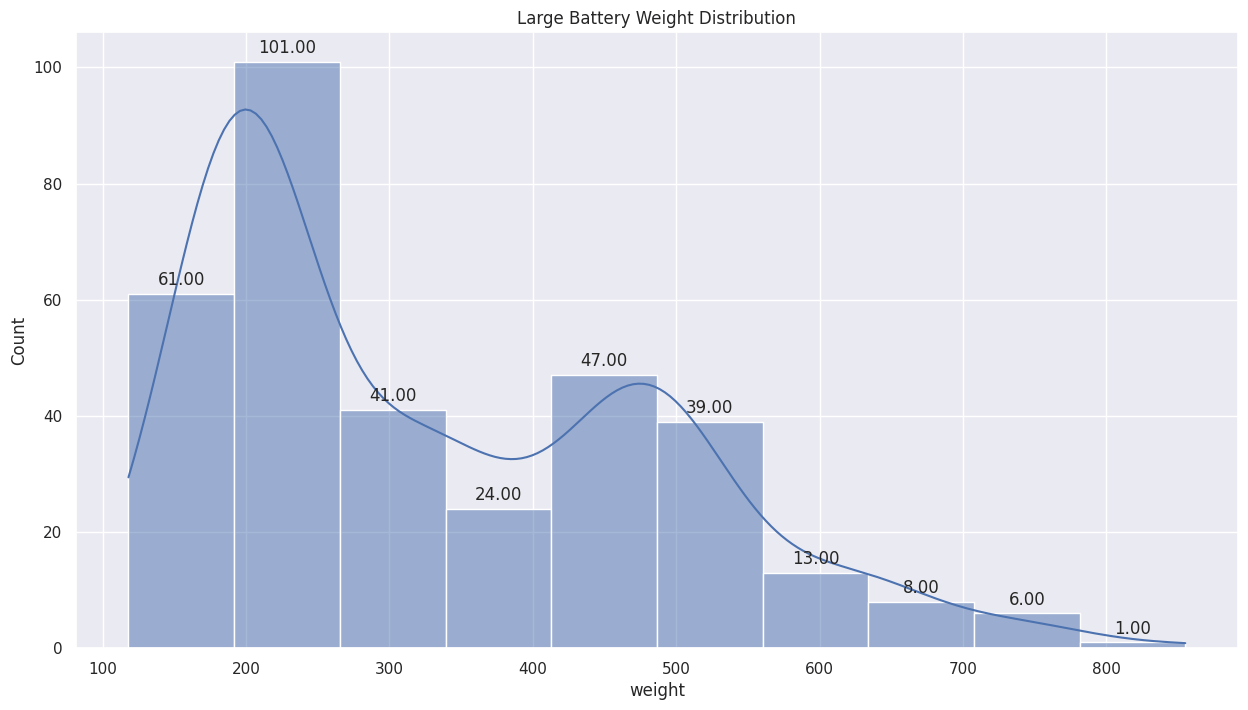

In [ ]:
#visualize the distribution of weight for large battery devices
plt.figure(figsize=(15,8))
large_battery_plot = sns.histplot(data=large_battery, x='weight', kde=True)
for p in large_battery_plot.patches:
  large_battery_plot.annotate(format(p.get_height(), '.2f'), (p.get_x() + p.get_width() / 2., p.get_height()),  ha = 'center', va = 'center', xytext = (0, 10), textcoords = 'offset points')
plt.title('Large Battery Weight Distribution')
plt.show()



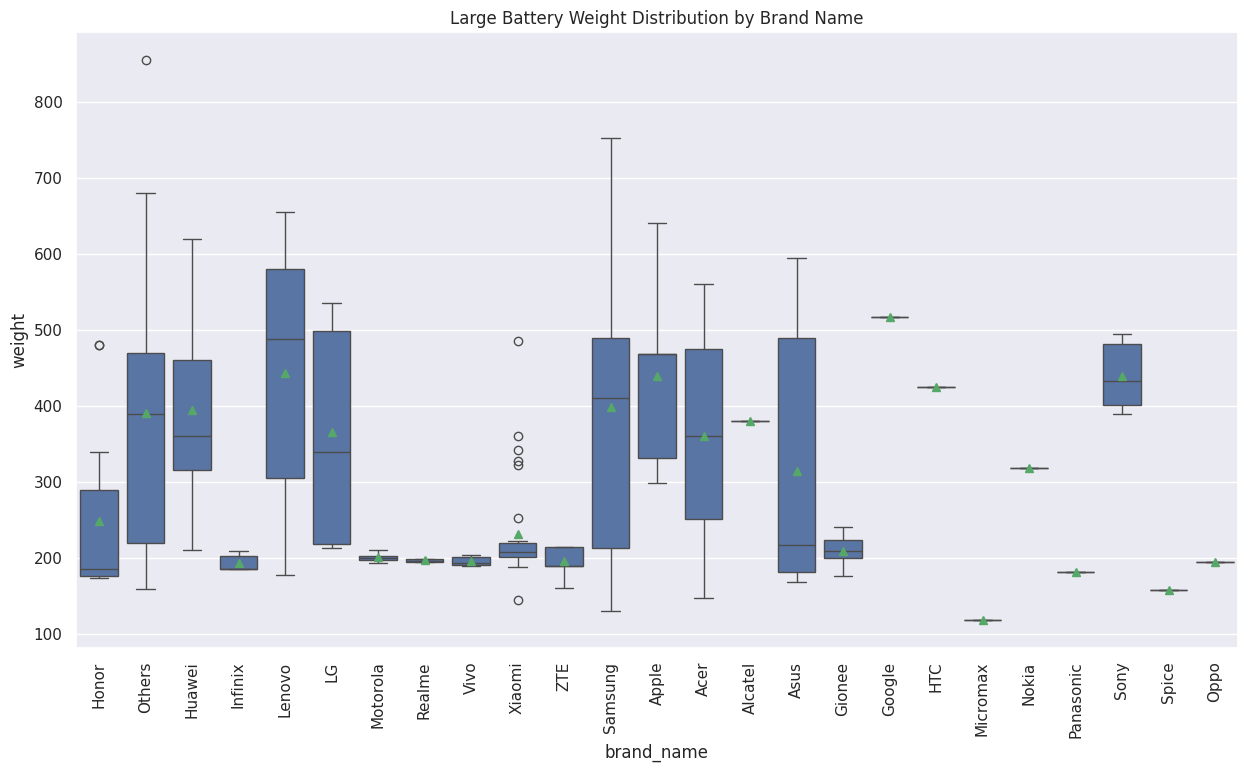

In [ ]:
#visualize the distribution of weight for large battery devices by Brand Name
plt.figure(figsize=(15,8))
sns.boxplot(data=large_battery, x='brand_name', y='weight', showmeans=True)
plt.xticks(rotation=90)
plt.title('Large Battery Weight Distribution by Brand Name')
plt.show()

In [ ]:
large_battery.groupby('brand_name')['weight'].mean().sort_values(ascending=False)

brand_name
Google       517.000000
Lenovo       442.721429
Apple        439.558824
Sony         439.500000
HTC          425.000000
Samsung      398.352000
Huawei       394.486486
Others       390.546341
Alcatel      380.000000
LG           366.058333
Acer         360.000000
Nokia        318.000000
Asus         313.772727
Honor        248.714286
Xiaomi       231.500000
Gionee       209.430000
Motorola     200.757143
Realme       196.833333
Vivo         195.630769
ZTE          195.400000
Oppo         195.000000
Infinix      193.000000
Panasonic    182.000000
Spice        158.000000
Micromax     118.000000
Name: weight, dtype: float64

In [ ]:
large_battery[large_battery['brand_name']== 'Micromax']

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
1916,Micromax,Android,20.32,no,no,5.0,2.0,16.0,4.0,4800.0,118.0,2013,1032,4.344325,5.143942


- Among with devices with a large battery (greater than 4500 mAh) Google devices on average weigh the most at 517g, followed by Lenovo, Apple, Sony and HTC all with an average device weight over 400 grams

- Micromax has the lightest device with a large battery weighing in at 118 g

- The distribution of weight with a large a battery is skewed to the right

####Large Screen Size  

In [ ]:
#Create a variable of a data set containing screens larger than 6 inches
large_screen = df1[df1['screen_size']> 6 *2.54] #1 inch = 2.54 CM
large_screen.shape

(1099, 15)

- There are 1099 phones with a screen size larger than 6 inches

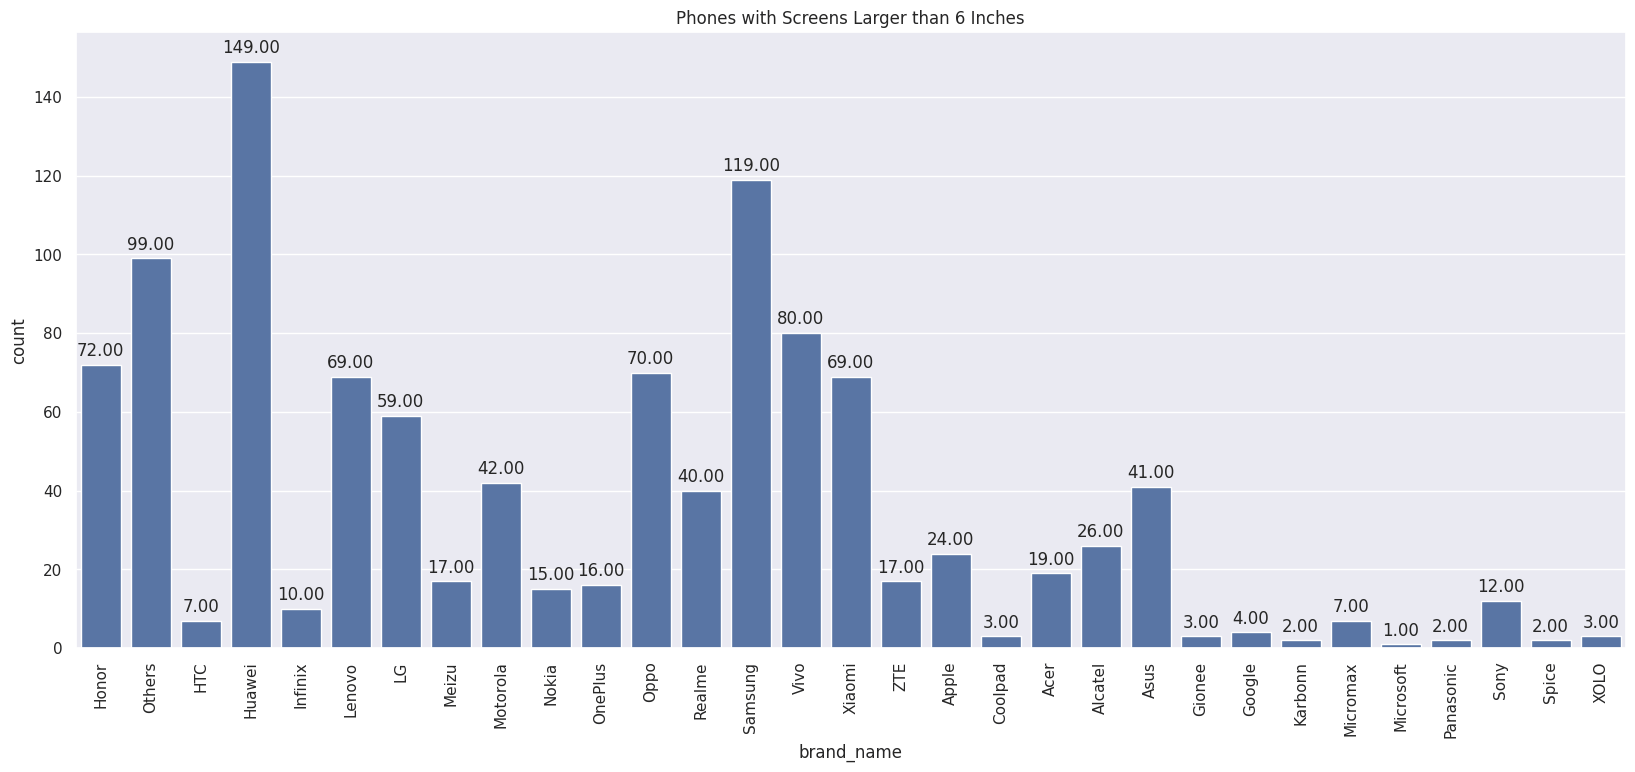

In [ ]:
#visualize the number of phones with screens larger than 6 inches for each brand
plt.figure(figsize=(20,8))
large_screen_plot = sns.countplot(data=large_screen, x='brand_name')
plt.xticks(rotation=90)
plt.title('Phones with Screens Larger than 6 Inches')
for p in large_screen_plot.patches:
  large_screen_plot.annotate(format(p.get_height(), '.2f'), (p.get_x() + p.get_width() / 2., p.get_height()),  ha = 'center', va = 'center', xytext = (0, 10), textcoords = 'offset points')
plt.show()

In [ ]:
large_screen['brand_name'].value_counts()

Huawei       149
Samsung      119
Others        99
Vivo          80
Honor         72
Oppo          70
Xiaomi        69
Lenovo        69
LG            59
Motorola      42
Asus          41
Realme        40
Alcatel       26
Apple         24
Acer          19
ZTE           17
Meizu         17
OnePlus       16
Nokia         15
Sony          12
Infinix       10
HTC            7
Micromax       7
Google         4
Coolpad        3
Gionee         3
XOLO           3
Karbonn        2
Panasonic      2
Spice          2
Microsoft      1
Name: brand_name, dtype: int64

- There are 1099 devices with a large screen size (greater than 6 inches)
- Huawei and Samsung have the most devices with large screens, with 149 and 119, respectively.
- The 'other' category has 99 devices, followed by Vivo and Honor with 80 and 82 respectively.
- Microsoft has only 1 device with a screen larger than 6 inches.

#### Selfie Camera over 8 Mega Pixels

In [ ]:
#create a variable data set with selfie camera quality above 8mp
quality_selfie = df1[df1['selfie_camera_mp']> 8]
quality_selfie.shape

(655, 15)

- There are 655 devices with selfie cameras above 8MP

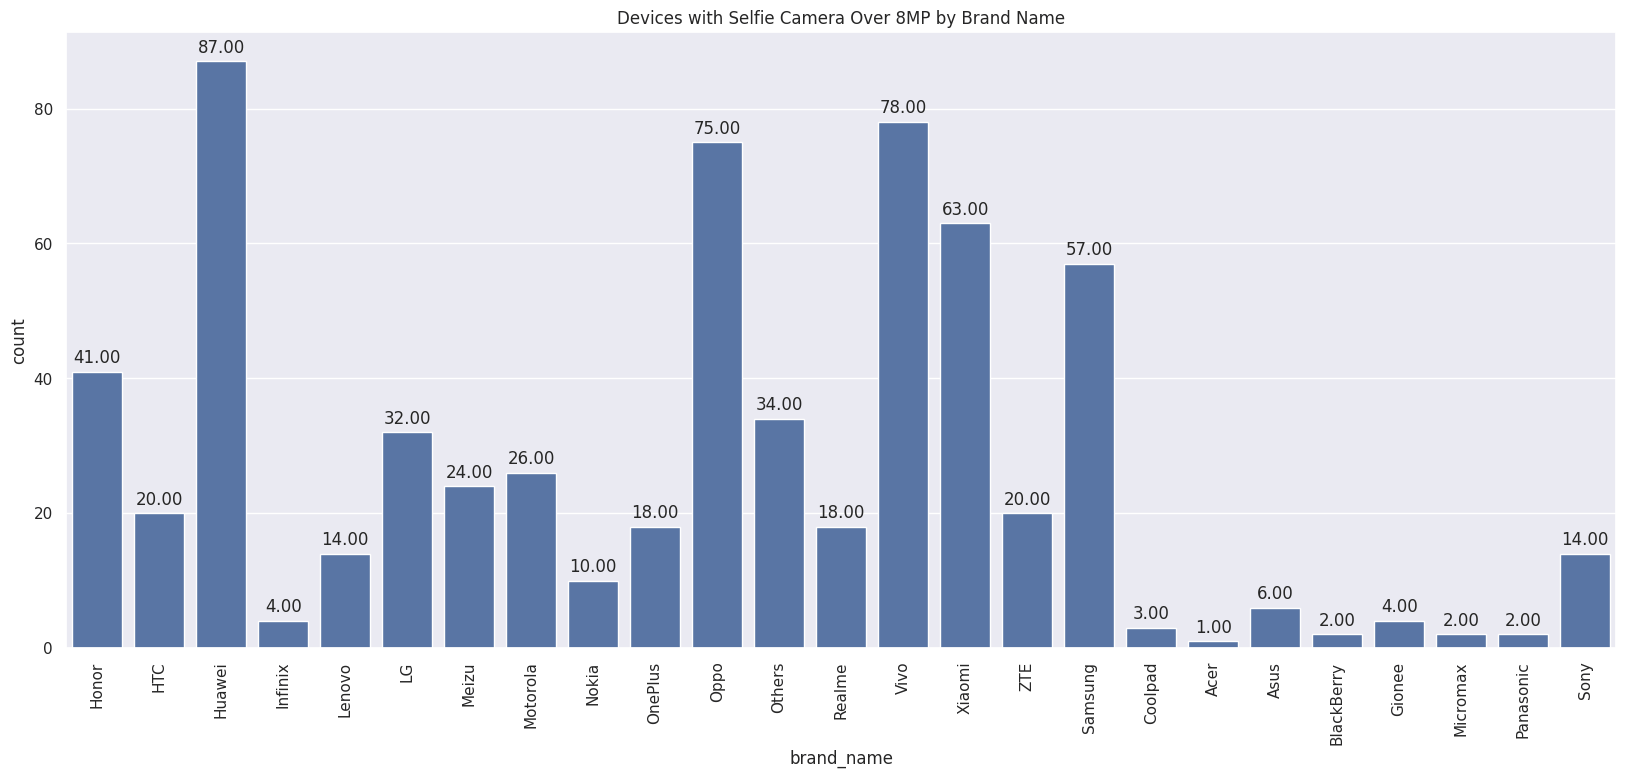

In [ ]:
#visualizing the data set
plt.figure(figsize=(20,8))
quality_selfie_plot = sns.countplot(data=quality_selfie, x='brand_name')
plt.xticks(rotation=90)
plt.title('Devices with Selfie Camera Over 8MP by Brand Name')
for p in quality_selfie_plot.patches:
  quality_selfie_plot.annotate(format(p.get_height(), '.2f'), (p.get_x() + p.get_width() / 2., p.get_height()),  ha = 'center', va = 'center', xytext = (0, 10), textcoords = 'offset points')
plt.show()

- The brand with the most devices with a high quality selfie camera is Huawei (87), followed by Xiaomi (78) and Oppo (75)

- Acer has only 1 device with a high quality selfie camera

## Data Preprocessing

### Missing Value Treatment

In [ ]:
#create another copy of the dataset to preserve the dataset we used for EDA
df2 = df1.copy()

In [ ]:
#find the missing values
df2.isnull().sum()

brand_name                 0
os                         0
screen_size                0
4g                         0
5g                         0
main_camera_mp           179
selfie_camera_mp           2
int_memory                 4
ram                        4
battery                    6
weight                     7
release_year               0
days_used                  0
normalized_used_price      0
normalized_new_price       0
dtype: int64

In [ ]:
#create a list of columns with missing data
cols_missing = ['main_camera_mp', 'selfie_camera_mp', 'int_memory', 'ram', 'battery', 'weight']
cols_missing

['main_camera_mp',
 'selfie_camera_mp',
 'int_memory',
 'ram',
 'battery',
 'weight']

- From the EDA portion we can see in many of the visualizations the presence of outliers in many of the columns. Therefore we will impute values with the median rather than the mean, since median is less sensitive than mean to outlier influence.

- The columns missing data are all in reference to the hardware of the device therefor we should group by columns which differentiate the hardware used in the device. There are two columns we can use which will have an influence on the hardware.

- brand_name and release_year will influence the hardware used in the device

In [ ]:
#impute the missing values in each column with the median of devices grouped by brand name and release
for col in cols_missing:
  df2[col] = df2[col].fillna(
      value=df2.groupby(['brand_name', 'release_year'])[col].transform('median')
  )

In [ ]:
#check again for missing values
df2.isnull().sum()

brand_name                 0
os                         0
screen_size                0
4g                         0
5g                         0
main_camera_mp           179
selfie_camera_mp           2
int_memory                 0
ram                        0
battery                    6
weight                     7
release_year               0
days_used                  0
normalized_used_price      0
normalized_new_price       0
dtype: int64

In [ ]:
#Use .loc to find the rows with missing data in selfie camera mp
df2.loc[df2['selfie_camera_mp'].isnull()]

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
1080,Google,Android,15.32,yes,no,12.2,NaN,64.0,4.0,3430.0,184.0,2018,475,5.573826,6.865974
1081,Google,Android,12.83,yes,no,12.2,NaN,64.0,4.0,2915.0,148.0,2018,424,4.464988,6.745083


In [ ]:
#pull the devices with brand name google, to check data to adjust the code for imputation
df2.loc[df2['brand_name']== 'Google']

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
1080,Google,Android,15.32,yes,no,12.2,NaN,64.0,4.0,3430.0,184.0,2018,475,5.573826,6.865974
1081,Google,Android,12.83,yes,no,12.2,NaN,64.0,4.0,2915.0,148.0,2018,424,4.464988,6.745083
1082,Google,Android,12.70,yes,no,12.2,8.0,64.0,4.0,2700.0,143.0,2017,890,4.825028,6.310845
1083,Google,Android,15.24,yes,no,12.2,8.0,64.0,4.0,3520.0,175.0,2017,554,5.247761,6.272367
1084,Google,Android,12.83,yes,no,12.3,8.0,32.0,4.0,3450.0,168.0,2016,1021,5.042586,5.936956
1085,Google,Android,12.70,yes,no,12.3,8.0,32.0,4.0,2770.0,143.0,2016,848,4.565077,5.671810
1086,Google,Android,25.45,no,no,8.0,2.0,32.0,4.0,9240.0,517.0,2015,584,5.032201,5.826059
3187,Google,Android,15.32,yes,no,12.2,8.0,64.0,6.0,3700.0,193.0,2019,487,4.870146,6.358102
3188,Google,Android,12.88,yes,no,12.2,8.0,64.0,6.0,2800.0,162.0,2019,203,5.153812,6.181362
3189,Google,Android,15.24,yes,no,12.2,8.0,64.0,4.0,3700.0,167.0,2019,318,4.877942,5.692553


In [ ]:
#Impute selfie camera mp by brand name median only since there is no reference for 2018 Google devices
df2['selfie_camera_mp'] = df2['selfie_camera_mp'].fillna(
    value= df2.groupby(['brand_name'])['selfie_camera_mp'].transform('median'))

In [ ]:
#check again for missing values
df2.isnull().sum()

brand_name                 0
os                         0
screen_size                0
4g                         0
5g                         0
main_camera_mp           179
selfie_camera_mp           0
int_memory                 0
ram                        0
battery                    6
weight                     7
release_year               0
days_used                  0
normalized_used_price      0
normalized_new_price       0
dtype: int64

In [ ]:
#pull the data for main camera mp to check the data to adjust code for imputation
main_camera_null_values = df2.loc[df2['main_camera_mp'].isnull()]
main_camera_null_values['brand_name'].value_counts()

Realme        36
Xiaomi        23
Oppo          20
Motorola      18
OnePlus       17
Meizu         15
Vivo          14
Infinix       10
Sony           7
ZTE            4
Asus           4
BlackBerry     4
Coolpad        3
Lava           2
Panasonic      2
Name: brand_name, dtype: int64

In [ ]:
#referencing sum of variable to missing values to verify all data is being represented
main_camera_null_values['brand_name'].value_counts().sum()

179

- When looking through the null values for main camera mp rows, all rows show an actual brand, and none are in the 'other' category.

- Therefore it is safe to impute the median on solely the brand, since there is no reference point to impute the values when grouping by both brand name and release year.

In [ ]:
#imputing median for main camera mp
df2['main_camera_mp'] = df2['main_camera_mp'].fillna(
    value= df2.groupby(['brand_name'])['main_camera_mp'].transform('median'))

In [ ]:
#checking to see remaining missing values
df2.isnull().sum()

brand_name                0
os                        0
screen_size               0
4g                        0
5g                        0
main_camera_mp           10
selfie_camera_mp          0
int_memory                0
ram                       0
battery                   6
weight                    7
release_year              0
days_used                 0
normalized_used_price     0
normalized_new_price      0
dtype: int64

- We still see that there are 10 missing values under main camera

In [ ]:
#Check the data for remaining missing values
df2.loc[df2['main_camera_mp'].isnull()]

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
59,Infinix,Android,17.32,yes,no,NaN,8.0,32.0,2.0,6000.0,209.0,2020,245,4.282068,4.597642
60,Infinix,Android,15.39,yes,no,NaN,8.0,64.0,4.0,5000.0,185.0,2020,173,4.363608,4.711780
61,Infinix,Android,15.39,yes,no,NaN,8.0,32.0,2.0,5000.0,185.0,2020,256,4.181439,4.505460
62,Infinix,Android,15.39,yes,no,NaN,16.0,32.0,3.0,4000.0,178.0,2019,316,4.555244,4.602166
63,Infinix,Android,15.29,yes,no,NaN,16.0,32.0,2.0,4000.0,165.0,2019,468,4.416670,4.871297
278,Infinix,Android,17.32,yes,no,NaN,8.0,32.0,2.0,6000.0,209.0,2020,320,4.405133,4.605370
279,Infinix,Android,15.39,yes,no,NaN,8.0,64.0,4.0,5000.0,185.0,2020,173,4.495913,4.702115
280,Infinix,Android,15.39,yes,no,NaN,8.0,32.0,2.0,5000.0,185.0,2020,329,4.370713,4.487287
281,Infinix,Android,15.39,yes,no,NaN,16.0,32.0,3.0,4000.0,178.0,2019,356,4.417997,4.605970
282,Infinix,Android,15.29,yes,no,NaN,16.0,32.0,2.0,4000.0,165.0,2019,497,4.423289,4.866072


- The missing data on main camera mp is due to the brand name infinix
- Since there's no reference for the data under the brand name for main camera mp, we would either have to research the data by looking at the other specs to see if we can match it to a model and gather the info or impute based on another variable.

In [ ]:
#Check to see what other rows have the brand name as Infinix
df2.loc[df2['brand_name']== 'Infinix']

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
59,Infinix,Android,17.32,yes,no,NaN,8.0,32.0,2.0,6000.0,209.0,2020,245,4.282068,4.597642
60,Infinix,Android,15.39,yes,no,NaN,8.0,64.0,4.0,5000.0,185.0,2020,173,4.363608,4.711780
61,Infinix,Android,15.39,yes,no,NaN,8.0,32.0,2.0,5000.0,185.0,2020,256,4.181439,4.505460
62,Infinix,Android,15.39,yes,no,NaN,16.0,32.0,3.0,4000.0,178.0,2019,316,4.555244,4.602166
63,Infinix,Android,15.29,yes,no,NaN,16.0,32.0,2.0,4000.0,165.0,2019,468,4.416670,4.871297
278,Infinix,Android,17.32,yes,no,NaN,8.0,32.0,2.0,6000.0,209.0,2020,320,4.405133,4.605370
279,Infinix,Android,15.39,yes,no,NaN,8.0,64.0,4.0,5000.0,185.0,2020,173,4.495913,4.702115
280,Infinix,Android,15.39,yes,no,NaN,8.0,32.0,2.0,5000.0,185.0,2020,329,4.370713,4.487287
281,Infinix,Android,15.39,yes,no,NaN,16.0,32.0,3.0,4000.0,178.0,2019,356,4.417997,4.605970
282,Infinix,Android,15.29,yes,no,NaN,16.0,32.0,2.0,4000.0,165.0,2019,497,4.423289,4.866072


- Since there's no reference for the data under the brand name for main camera mp, we would either have to research the data by looking at the other specs to see if we can match it to a model and gather the info or impute based on another variable.

In [ ]:
#verify that all Infinix devices are missing the data for main camera mp
len(df2.loc[df2['brand_name']== 'Infinix'])

10

- Since there is no reference data for Main Camera mp for the infinix brand, rather than imputing with the median for all devices. It would be better to impute using the release year, so that the assumed MP for the main camera will fall in line with available technology.


In [ ]:
#impute the null values for main camera np with the median of the corresponding release year
df2['main_camera_mp'] = df2['main_camera_mp'].fillna(
    df2.groupby(['release_year'])['main_camera_mp'].transform('median')
)
# Check to see that missing values were filled
df2.isnull().sum()

brand_name               0
os                       0
screen_size              0
4g                       0
5g                       0
main_camera_mp           0
selfie_camera_mp         0
int_memory               0
ram                      0
battery                  6
weight                   7
release_year             0
days_used                0
normalized_used_price    0
normalized_new_price     0
dtype: int64

- All the values for main camera megapixels have been treated

- We still ahve weight with 6 null values and weight with 7 null values


In [ ]:
#Locate the rows with weight as missing value
df2.loc[df2['weight'].isnull()]

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
3002,XOLO,Android,12.70,yes,no,13.0,5.0,32.0,4.0,2400.0,NaN,2015,576,4.165890,4.930437
3003,XOLO,Android,12.83,yes,no,8.0,5.0,16.0,4.0,3200.0,NaN,2015,800,4.282068,5.189228
3004,XOLO,Android,12.70,no,no,8.0,2.0,32.0,4.0,2100.0,NaN,2015,878,3.879706,4.081090
3005,XOLO,Android,10.29,no,no,5.0,0.3,32.0,4.0,1800.0,NaN,2015,1036,3.823847,4.396053
3006,XOLO,Android,12.70,no,no,5.0,0.3,16.0,4.0,2500.0,NaN,2015,679,3.837084,4.347176
3007,XOLO,Windows,12.70,no,no,8.0,2.0,32.0,4.0,2200.0,NaN,2015,838,3.707210,4.791733
3008,XOLO,Android,12.70,no,no,8.0,5.0,32.0,4.0,2500.0,NaN,2015,1045,4.184642,4.785406


In [ ]:
#pull up all the rows with XOLO as the brand for reference on how to treat the rows with missing values in weight
xolo_weight = df2.loc[df2['brand_name']== 'XOLO']
xolo_weight


,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
3002,XOLO,Android,12.70,yes,no,13.00,5.00,32.0,4.0,2400.0,NaN,2015,576,4.165890,4.930437
3003,XOLO,Android,12.83,yes,no,8.00,5.00,16.0,4.0,3200.0,NaN,2015,800,4.282068,5.189228
3004,XOLO,Android,12.70,no,no,8.00,2.00,32.0,4.0,2100.0,NaN,2015,878,3.879706,4.081090
3005,XOLO,Android,10.29,no,no,5.00,0.30,32.0,4.0,1800.0,NaN,2015,1036,3.823847,4.396053
3006,XOLO,Android,12.70,no,no,5.00,0.30,16.0,4.0,2500.0,NaN,2015,679,3.837084,4.347176
3007,XOLO,Windows,12.70,no,no,8.00,2.00,32.0,4.0,2200.0,NaN,2015,838,3.707210,4.791733
3008,XOLO,Android,12.70,no,no,8.00,5.00,32.0,4.0,2500.0,NaN,2015,1045,4.184642,4.785406
3009,XOLO,Android,12.83,no,no,13.00,2.00,32.0,4.0,2600.0,120.00,2014,1008,3.916214,4.863990
3010,XOLO,Android,12.70,no,no,8.00,2.00,32.0,4.0,2100.0,120.00,2014,782,3.993603,4.697658
3011,XOLO,Android,12.70,no,no,8.00,5.00,32.0,4.0,2500.0,120.00,2014,956,3.977811,4.791401


<Axes: xlabel='weight'>

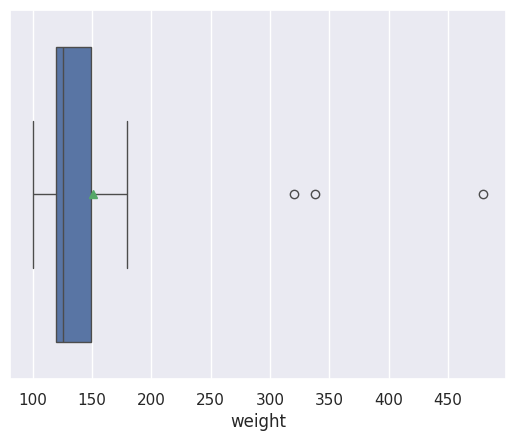

In [ ]:
#visualize distribution of weight
sns.boxplot(data=xolo_weight, x='weight', showmeans=True)

In [ ]:
#checking summary of weight for Xolo Brand
xolo_weight['weight'].describe().T

count     42.000000
mean     151.019048
std       69.197676
min      100.000000
25%      120.000000
50%      126.000000
75%      148.850000
max      480.000000
Name: weight, dtype: float64

- Visually it seems safe to impute the weight based on the brand name since we can't impute based on the release year. We will be using the median to account for outlier sensitivity.

In [ ]:
# Impute the missing data with the median weight based on the brand name
df2['weight'] = df2['weight'].fillna(
    df2.groupby(['brand_name'])['weight'].transform('median')
)
#Checking to see what missing values are left
df2.isnull().sum()

brand_name               0
os                       0
screen_size              0
4g                       0
5g                       0
main_camera_mp           0
selfie_camera_mp         0
int_memory               0
ram                      0
battery                  6
weight                   0
release_year             0
days_used                0
normalized_used_price    0
normalized_new_price     0
dtype: int64

- Weight has been treated

- All that is left to be treated is the missing values for battery

In [ ]:
#Pull the data for missing values on the battery column
df2.loc[df2['battery'].isnull()]

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
1829,Meizu,Android,12.83,yes,no,13.0,5.0,16.00,4.00,NaN,145.0,2014,986,4.177919,4.863604
1831,Meizu,Android,12.83,yes,no,20.7,5.0,16.00,4.00,NaN,158.0,2014,1043,4.878855,5.990639
1832,Meizu,Android,13.61,yes,no,20.7,2.0,16.00,4.00,NaN,147.0,2014,1007,4.742320,5.826118
1962,Microsoft,Windows,25.55,no,no,5.0,3.5,32.00,4.00,NaN,675.9,2013,931,5.230574,5.802753
2058,Nokia,Others,5.18,no,no,0.3,0.0,0.06,0.02,NaN,81.0,2016,815,2.718660,3.374511
2059,Nokia,Others,5.18,no,no,0.3,0.0,0.06,0.02,NaN,82.6,2016,1023,2.765060,3.657905


In [ ]:
#Impute the battery values based on the brand name of the device
df2['battery'] = df2['battery'].fillna(
    df2.groupby(['brand_name'])['battery'].transform('median')
)

df2.isnull().sum()

brand_name               0
os                       0
screen_size              0
4g                       0
5g                       0
main_camera_mp           0
selfie_camera_mp         0
int_memory               0
ram                      0
battery                  0
weight                   0
release_year             0
days_used                0
normalized_used_price    0
normalized_new_price     0
dtype: int64

- All missing data has been treated

###Feature Engineering

- The main feature we can change is the release year to better represent the age of the phone. Rather than having the year, we can quantify how many years ago the phone was released.

- Since the data was collected in 2021 we'll set that as the base.

In [ ]:
# Create a new column showing the years since realease of the devices
df2['years_since_release'] = 2021 - df2['release_year']
#drop the release_year column since we've created a new column which represents the release year in a simpler fashion
df2.drop('release_year', axis=1, inplace=True)

In [ ]:
#Summarry of the new column
df2['years_since_release'].describe().T

count    3454.000000
mean        5.034742
std         2.298455
min         1.000000
25%         3.000000
50%         5.500000
75%         7.000000
max         8.000000
Name: years_since_release, dtype: float64

###Outlier Treatment

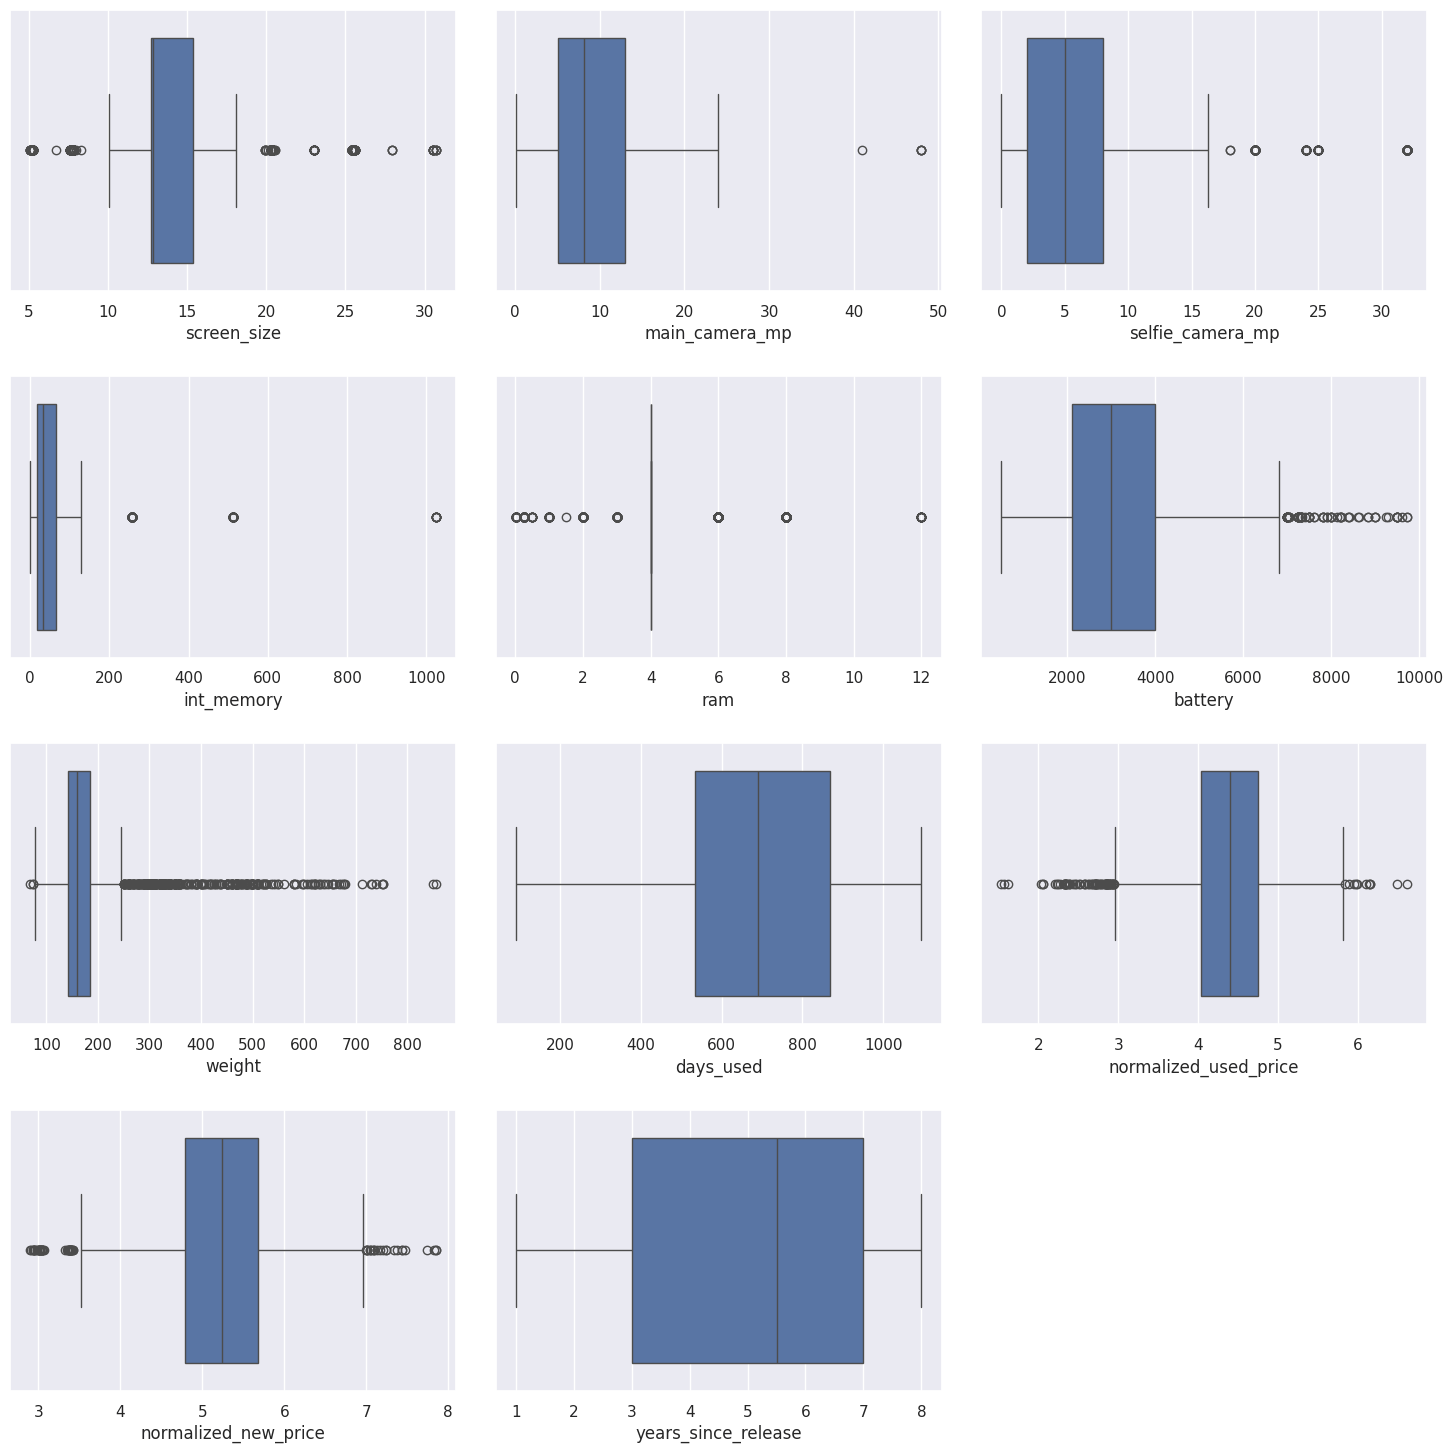

In [ ]:
# outlier detection using boxplot
num_cols = df2.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(15, 15))

for i, variable in enumerate(num_cols):
    plt.subplot(4, 3, i + 1)
    sns.boxplot(data=df2, x=variable)
    plt.tight_layout(pad=2)

plt.show()

- There are numerous outliers in most of the variables.

- The variables of interest from these plots are: main_camera_mp, selfie_camera_mp, int_memory and RAM.

- We will explore each of these more deeply to see what course of action, if any, we will choose to do on these values.



In [ ]:
#create another copy of the data to preserve what we have done so far
df3 = df2.copy()

df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3454 entries, 0 to 3453
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   brand_name             3454 non-null   object 
 1   os                     3454 non-null   object 
 2   screen_size            3454 non-null   float64
 3   4g                     3454 non-null   object 
 4   5g                     3454 non-null   object 
 5   main_camera_mp         3454 non-null   float64
 6   selfie_camera_mp       3454 non-null   float64
 7   int_memory             3454 non-null   float64
 8   ram                    3454 non-null   float64
 9   battery                3454 non-null   float64
 10  weight                 3454 non-null   float64
 11  days_used              3454 non-null   int64  
 12  normalized_used_price  3454 non-null   float64
 13  normalized_new_price   3454 non-null   float64
 14  years_since_release    3454 non-null   int64  
dtypes: f

-Before treating the outliers, lets see how many other devices of the same brand are in the data set, to see how sensitive the data is to either removal or imputation.

In [ ]:
#Check the value counts of each brand
df3['brand_name'].value_counts()

Others        502
Samsung       341
Huawei        251
LG            201
Lenovo        171
ZTE           140
Xiaomi        132
Oppo          129
Asus          122
Alcatel       121
Micromax      117
Vivo          117
Honor         116
HTC           110
Nokia         106
Motorola      106
Sony           86
Meizu          62
Gionee         56
Acer           51
XOLO           49
Panasonic      47
Realme         41
Apple          39
Lava           36
Celkon         33
Spice          30
Karbonn        29
Coolpad        22
BlackBerry     22
Microsoft      22
OnePlus        22
Google         15
Infinix        10
Name: brand_name, dtype: int64

- This list can be used for reference on how to treat the outliers we will be exploring

In [ ]:
# Check to see which have high mp
df3.loc[df3['main_camera_mp'] > 30]

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,days_used,normalized_used_price,normalized_new_price,years_since_release
210,ZTE,Android,16.89,yes,no,48.0,16.0,128.0,8.0,5000.0,215.0,336,5.668052,6.708780,2
215,ZTE,Android,16.89,yes,no,48.0,16.0,64.0,6.0,5000.0,215.0,506,5.263726,6.217723,2
2097,Nokia,Windows,10.29,yes,no,41.0,1.2,32.0,4.0,2000.0,158.0,988,5.105097,5.989287,8
3240,Motorola,Android,15.34,yes,no,48.0,25.0,128.0,4.0,3600.0,165.0,371,5.325933,5.541224,2
3381,Motorola,Android,15.34,yes,no,48.0,25.0,128.0,4.0,3600.0,165.0,422,5.331027,5.541224,2


- There are 5 devices which have main camera mega pixels above 40mp
- The Nokia device is 8 years since its release, which stands out since it's unlikely that a device from 2013 would have this many megapixels, especially when the selfie camera is so low.
- The other 4 devices still stand out, but we'll reference it to other devices of the same brand.
- When referencing the brands for sensitivity, each of these brands have over a 100 devices and thus would not be very sensitive to removal or imputation.

In [ ]:
#find the index position for the variable we want to impute with the median value
df3.iloc[2097,:]

brand_name                  Nokia
os                        Windows
screen_size                 10.29
4g                            yes
5g                             no
main_camera_mp               41.0
selfie_camera_mp              1.2
int_memory                   32.0
ram                           4.0
battery                    2000.0
weight                      158.0
days_used                     988
normalized_used_price    5.105097
normalized_new_price     5.989287
years_since_release             8
Name: 2097, dtype: object

In [ ]:
#verfiy the position of the variable
df3.iloc[2097,5]

41.0

In [ ]:
#changing the data to NaN for imputation
df3.iloc[2097,5] = np.nan
df3.iloc[2097,5]

nan

In [ ]:
#imputing with the median pertaining to the brand name and the year release
df3['main_camera_mp'] = df3['main_camera_mp'].fillna(
    df3.groupby(['brand_name', 'years_since_release'])['main_camera_mp'].transform('median')
)
df3.iloc[2097,5]

5.0

In [ ]:
# Checking to see how the imputation looks compared to nearby data points which it seems to fit pretty well
df3.iloc[2096 : 2099,]

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,days_used,normalized_used_price,normalized_new_price,years_since_release
2096,Nokia,Windows,10.34,yes,no,5.0,0.3,32.00,4.00,2000.0,159.0,797,4.053002,5.070726,8
2097,Nokia,Windows,10.29,yes,no,5.0,1.2,32.00,4.00,2000.0,158.0,988,5.105097,5.989287,8
2098,Nokia,Others,5.18,no,no,1.3,0.0,0.06,0.02,1020.0,89.6,955,4.035479,4.076011,8


In [ ]:
#Looking at the data for ZTE to see how the main camera mp compares to other ZTE devices
df3.loc[df3['brand_name'] == 'ZTE'].sort_values('main_camera_mp', ascending = False)

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,days_used,normalized_used_price,normalized_new_price,years_since_release
210,ZTE,Android,16.89,yes,no,48.00,16.0,128.0,8.00,5000.0,215.0,336,5.668052,6.708780,2
215,ZTE,Android,16.89,yes,no,48.00,16.0,64.0,6.00,5000.0,215.0,506,5.263726,6.217723,2
3069,ZTE,Android,15.24,yes,no,24.00,8.0,128.0,4.00,3800.0,185.0,492,5.161065,5.990264,3
3101,ZTE,Android,12.75,yes,no,23.00,13.0,64.0,4.00,3000.0,158.0,835,4.932025,5.386740,5
3107,ZTE,Android,12.83,yes,no,20.00,8.0,64.0,4.00,3250.0,175.0,903,4.453882,5.487408,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3184,ZTE,Android,10.16,no,no,3.15,1.0,16.0,4.00,1600.0,140.0,782,3.745023,4.860975,8
3185,ZTE,Android,7.75,no,no,3.15,1.0,16.0,4.00,1500.0,140.0,1003,3.767460,5.008566,8
3166,ZTE,Android,10.16,no,no,3.15,5.0,512.0,0.25,1400.0,120.0,1006,3.173878,4.096176,7
3170,ZTE,Others,10.16,no,no,3.15,5.0,16.0,4.00,1400.0,125.0,1007,3.764451,4.244344,7


In [ ]:
#comparing to newer devices
df3.loc[df3['brand_name'] == 'ZTE'].sort_values('years_since_release', ascending = True)

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,days_used,normalized_used_price,normalized_new_price,years_since_release
204,ZTE,Android,16.89,yes,yes,13.0,12.0,256.0,8.0,5100.0,215.0,235,5.390851,6.394694,1
3326,ZTE,Android,16.43,yes,yes,13.0,20.0,128.0,6.0,4000.0,168.0,217,5.371242,6.232743,1
3327,ZTE,Android,16.89,yes,yes,13.0,8.0,128.0,8.0,4500.0,218.0,133,5.103883,6.198784,1
205,ZTE,Android,16.89,yes,yes,13.0,12.0,128.0,6.0,5100.0,210.0,278,4.652054,5.740147,1
207,ZTE,Android,15.47,yes,no,16.0,5.0,32.0,3.0,3200.0,165.0,325,4.408060,4.485936,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3174,ZTE,Android,12.70,yes,no,8.0,1.0,16.0,4.0,2300.0,130.0,916,3.754199,5.735636,8
3173,ZTE,Android,10.34,no,no,13.0,5.0,16.0,4.0,2000.0,120.0,966,4.059581,5.436339,8
3172,ZTE,Android,12.70,yes,no,13.0,5.0,16.0,4.0,2300.0,126.0,567,4.169297,5.667672,8
3180,ZTE,Android,10.29,no,no,8.0,0.3,16.0,4.0,2000.0,146.0,939,3.617920,4.710971,8


- While these are particularly large, the devices are on the newer side, and the technology to have these MP's was available at the time
- We'll go ahead and leave these as they are

In [ ]:
#pull up the Motorola rows for reference
df3.loc[df3['brand_name'] == 'Motorola'].sort_values('main_camera_mp', ascending = False)

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,days_used,normalized_used_price,normalized_new_price,years_since_release
3381,Motorola,Android,15.34,yes,no,48.0,25.0,128.0,4.0,3600.0,165.0,422,5.331027,5.541224,2
3240,Motorola,Android,15.34,yes,no,48.0,25.0,128.0,4.0,3600.0,165.0,371,5.325933,5.541224,2
2012,Motorola,Android,12.75,yes,no,21.0,2.0,32.0,4.0,3900.0,169.0,564,4.911625,5.666046,7
1993,Motorola,Android,12.83,yes,no,21.0,5.0,32.0,4.0,3500.0,163.0,1041,4.434145,5.593744,5
1999,Motorola,Android,12.80,yes,no,21.0,5.0,32.0,4.0,3760.0,169.0,582,4.560696,5.634611,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019,Motorola,Android,10.24,no,no,5.0,2.0,16.0,4.0,1980.0,142.0,959,3.874736,4.621437,7
2020,Motorola,Android,10.24,no,no,5.0,2.0,16.0,4.0,1980.0,142.0,979,3.965185,4.488187,7
2021,Motorola,Android,10.29,no,no,5.0,1.3,32.0,4.0,2070.0,143.0,821,3.958334,4.939211,7
2028,Motorola,Android,7.75,no,no,5.0,2.0,16.0,4.0,1785.0,110.0,667,3.542697,5.020388,8


In [ ]:
#sort by years since release to compare to other values
df3.loc[df3['brand_name'] == 'Motorola'].sort_values('years_since_release', ascending = True)

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,days_used,normalized_used_price,normalized_new_price,years_since_release
108,Motorola,Android,15.37,yes,no,13.0,16.0,128.0,6.0,5000.0,210.0,242,4.829673,5.704849,1
3225,Motorola,Android,15.29,yes,no,13.0,5.0,32.0,2.0,3550.0,185.0,174,4.511189,4.848038,1
3226,Motorola,Android,15.37,yes,no,13.0,8.0,64.0,4.0,5000.0,200.0,352,4.454580,4.807294,1
3227,Motorola,Android,15.27,yes,no,13.0,5.0,32.0,2.0,3000.0,160.0,208,4.201404,4.410614,1
3228,Motorola,Android,15.34,yes,no,13.0,16.0,128.0,4.0,4000.0,192.0,186,4.670490,5.110481,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024,Motorola,Android,12.70,yes,no,10.0,2.0,16.0,4.0,2130.0,137.0,607,4.245204,5.524656,8
2025,Motorola,Android,12.70,yes,no,10.0,2.0,16.0,4.0,3500.0,167.0,715,4.122770,5.394309,8
2026,Motorola,Android,10.24,yes,no,10.0,2.0,16.0,4.0,2000.0,130.0,1044,4.292375,5.196119,8
2027,Motorola,Android,10.16,no,no,8.0,1.2,16.0,4.0,2000.0,120.0,944,4.488524,5.438384,8


- Similarly to ZTE we can leave these data points for the same rationale

In [ ]:
# Check to see which have high selfie camera mp
selfie_camera_outliers = df3.loc[df3['selfie_camera_mp'] > 30]
selfie_camera_outliers

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,days_used,normalized_used_price,normalized_new_price,years_since_release
16,Honor,Android,15.90,yes,no,13.0,32.0,128.0,6.0,3750.0,172.0,395,5.022366,5.517935,2
41,Huawei,Android,15.90,yes,no,13.0,32.0,64.0,6.0,4000.0,178.0,206,4.996536,5.294560,2
47,Huawei,Android,15.90,yes,no,13.0,32.0,128.0,6.0,4000.0,178.0,244,5.143475,5.670295,2
52,Huawei,Android,16.23,yes,no,13.0,32.0,128.0,8.0,3500.0,171.0,333,5.428205,5.965249,2
53,Huawei,Android,16.23,yes,no,13.0,32.0,128.0,8.0,3500.0,171.0,284,5.378560,5.885521,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3429,Samsung,Android,15.42,yes,no,8.0,32.0,128.0,6.0,4500.0,186.0,213,5.199546,5.946624,1
3431,Samsung,Android,15.42,yes,no,12.0,32.0,128.0,6.0,4500.0,179.0,202,5.302011,5.633539,2
3432,Samsung,Android,15.37,yes,no,12.0,32.0,64.0,4.0,4000.0,172.0,382,5.069219,5.405781,2
3437,Samsung,Android,15.42,yes,yes,12.0,32.0,128.0,6.0,4500.0,206.0,254,5.572306,6.742373,2


In [ ]:
#Check to see how many brands fall into this category
selfie_camera_outliers['brand_name'].nunique()

8

In [ ]:
#Check to see the years since these devices were released
selfie_camera_outliers['years_since_release'].value_counts()

2    59
1    35
Name: years_since_release, dtype: int64

- Since there is 8 different brand names with a high selfie camera mp, it seems to be fairly common
- Checking the year of release for device, all the devices are relatively new.
- Given these facts, we can safely assume that these selfie cameras are being represented correctly.

In [ ]:
# Check to see how many devices have internal memory greater than 400
int_memory_outliers = df3.loc[df3['int_memory'] > 400 ]
len(int_memory_outliers)

52

In [ ]:
#CHeck to see which brands are displaying outliers
print(int_memory_outliers['brand_name'].unique())
#Check to see how many brands different brands are outliers
print(int_memory_outliers['brand_name'].nunique())

['Huawei' 'Xiaomi' 'Alcatel' 'Others' 'Apple' 'Asus' 'BlackBerry' 'Celkon'
 'Gionee' 'Karbonn' 'Lava' 'Lenovo' 'Micromax' 'Oppo' 'Samsung' 'Spice'
 'ZTE']
17


- There's 52 devices across 17 brand_names with internal memory over 400 so we'll change the parameter to over 600

In [ ]:
#check to see how many devices have internal memory over 600
len(df3.loc[df3['int_memory'] > 600 ])

8

There are 8 devices over 600 gb of internal memory

In [ ]:
#Find the specific devices with internal memory over 600 and sort by years since release
df3.loc[df3['int_memory'] > 600].sort_values('years_since_release')

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,days_used,normalized_used_price,normalized_new_price,years_since_release
2355,Samsung,Android,15.34,yes,no,12.00,9.0,1024.0,4.0,4100.0,175.0,291,5.569718,6.957269,2
644,Apple,iOS,30.71,yes,no,12.00,7.0,1024.0,4.0,9720.0,631.0,543,5.808022,7.003847,3
645,Apple,iOS,27.94,yes,no,12.00,7.0,1024.0,4.0,7812.0,468.0,525,6.158969,6.778899,3
772,Asus,Android,12.70,no,no,8.00,0.3,1024.0,4.0,2500.0,160.0,860,3.523120,4.594413,7
791,Asus,Android,10.34,no,no,13.00,1.2,1024.0,4.0,1820.0,126.0,772,5.494953,5.555012,7
1468,Lava,Android,10.16,no,no,2.00,0.3,1024.0,4.0,1400.0,113.0,595,2.978077,3.934958,8
1940,Micromax,Android,10.08,no,no,3.15,0.3,1024.0,4.0,1450.0,118.0,836,3.437208,4.503912,8
2251,Others,Android,12.70,no,no,5.00,0.3,1024.0,4.0,2200.0,170.0,584,4.070905,5.135798,8


- There are 5 devices which seem to be released too early to have such a high internal memory capacity
- We can impute using the same strategy we used for main camera mp

In [ ]:
#index and replace all values of internal memory for devices over 3 years since release
df3.loc[(df3['int_memory'] > 600) & (df3['years_since_release'] > 3 ), ['int_memory']] = np.nan

In [ ]:
#check to see that 5 values were changed
df3.isnull().sum()

brand_name               0
os                       0
screen_size              0
4g                       0
5g                       0
main_camera_mp           0
selfie_camera_mp         0
int_memory               5
ram                      0
battery                  0
weight                   0
days_used                0
normalized_used_price    0
normalized_new_price     0
years_since_release      0
dtype: int64

In [ ]:
#impute null values with median corresponding to grouping by brand name and years since release
df3['int_memory'] = df3['int_memory'].fillna(df3.groupby(['brand_name', 'years_since_release'])['int_memory'].transform('median'))

In [ ]:
#check to see that null values were imputed
df3.isnull().sum()

brand_name               0
os                       0
screen_size              0
4g                       0
5g                       0
main_camera_mp           0
selfie_camera_mp         0
int_memory               0
ram                      0
battery                  0
weight                   0
days_used                0
normalized_used_price    0
normalized_new_price     0
years_since_release      0
dtype: int64

In [ ]:
#Check to see remaining outliers
df3.loc[df3['int_memory'] > 600]

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,days_used,normalized_used_price,normalized_new_price,years_since_release
644,Apple,iOS,30.71,yes,no,12.0,7.0,1024.0,4.0,9720.0,631.0,543,5.808022,7.003847,3
645,Apple,iOS,27.94,yes,no,12.0,7.0,1024.0,4.0,7812.0,468.0,525,6.158969,6.778899,3
2355,Samsung,Android,15.34,yes,no,12.0,9.0,1024.0,4.0,4100.0,175.0,291,5.569718,6.957269,2


In [ ]:
#spot check on the recently imputed values
df3.iloc[772]

brand_name                   Asus
os                        Android
screen_size                  12.7
4g                             no
5g                             no
main_camera_mp                8.0
selfie_camera_mp              0.3
int_memory                   16.0
ram                           4.0
battery                    2500.0
weight                      160.0
days_used                     860
normalized_used_price     3.52312
normalized_new_price     4.594413
years_since_release             7
Name: 772, dtype: object

In [ ]:
#Checking high values for RAM
len(df3.loc[df3['ram'] > 10 ])

18

-There are 18 devices with RAM over 10 GB

In [ ]:
#setting the RAM outliers as a variable
ram_outliers = df3.loc[df3['ram'] > 10 ]
ram_outliers

,brand_name,os,screen_size,4g,5g,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,days_used,normalized_used_price,normalized_new_price,years_since_release
44,Huawei,Android,16.59,yes,yes,13.0,16.0,512.0,12.0,4500.0,198.0,289,5.674182,7.438007,2
109,Motorola,Android,15.42,yes,yes,13.0,25.0,256.0,12.0,5000.0,203.0,220,5.186883,7.090785,1
120,OnePlus,Android,16.94,yes,yes,13.0,16.0,256.0,12.0,4085.0,206.0,458,5.713403,6.686161,2
198,Xiaomi,Android,20.12,yes,yes,12.0,20.0,512.0,12.0,4050.0,241.0,478,6.619433,7.823342,2
263,Huawei,Android,16.59,yes,yes,13.0,16.0,512.0,12.0,4500.0,198.0,488,5.995954,7.439289,2
328,Motorola,Android,15.42,yes,yes,13.0,25.0,256.0,12.0,5000.0,203.0,188,5.639813,7.087983,1
339,OnePlus,Android,16.94,yes,yes,13.0,16.0,256.0,12.0,4085.0,206.0,280,5.079850,6.685761,2
372,Samsung,Android,15.32,yes,yes,12.0,10.0,256.0,12.0,3500.0,168.0,190,4.997685,7.003629,2
3250,Oppo,Android,15.37,yes,yes,13.0,32.0,256.0,12.0,4025.0,171.0,227,5.447728,6.232743,1
3252,Oppo,Android,15.42,yes,yes,13.0,32.0,256.0,12.0,4260.0,217.0,193,5.742009,6.840536,1


In [ ]:
#check to see if there are older devices
ram_outliers['years_since_release'].value_counts()

1    10
2     8
Name: years_since_release, dtype: int64

- After diving into the data for outliers in RAM it seems reasonable to keep these values as is, due to the release year of the devices

In [ ]:
#create another copy of the data to preserve the adjustments made in outlier correction
df4 = df3.copy()

## EDA

- It is a good idea to explore the data once again after manipulating it.

In [ ]:
#Pull up the columns that we treated the missing values for in the previous section
cols_missing

['main_camera_mp',
 'selfie_camera_mp',
 'int_memory',
 'ram',
 'battery',
 'weight']

- The focus of this EDA is to visualize:
  - The data we treated for missing values: main_camera_mp, selfie_camera_mp, int_memory, ram, battery, and weight
  - The engineered features: years_since_release
  - The columns where outliers were treated: main_camera_mp and int_memory
  - Heatmap showing correlation

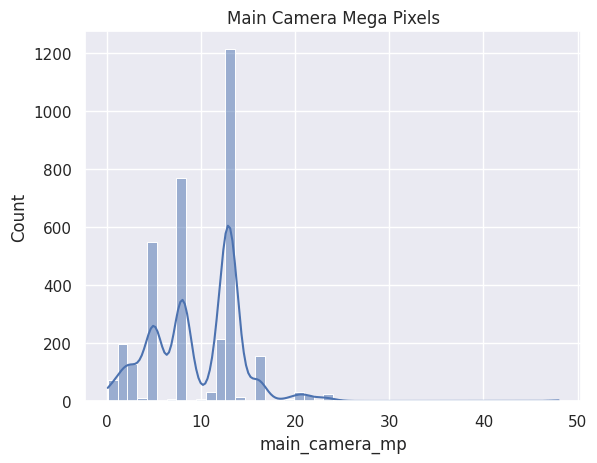

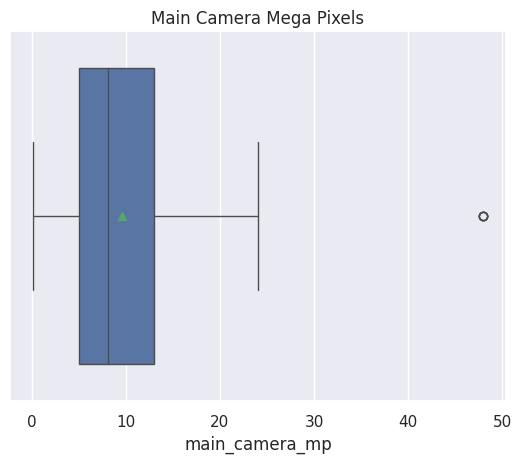

In [ ]:
# Visualize main camera mp
sns.histplot(data=df4, x= 'main_camera_mp', kde=True)
plt.title('Main Camera Mega Pixels')
plt.show()
sns.boxplot(data=df4, x= 'main_camera_mp', showmeans=True)
plt.title('Main Camera Mega Pixels')
plt.show()

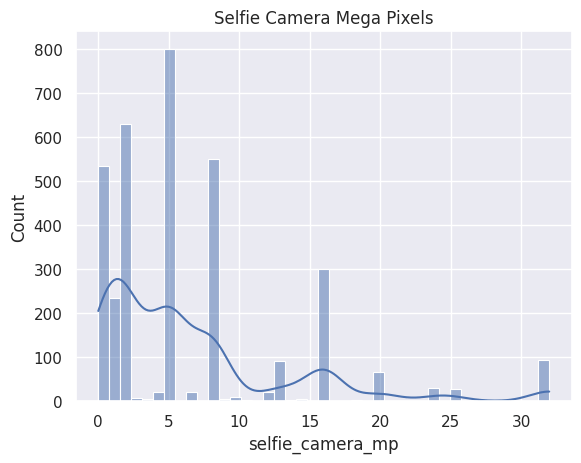

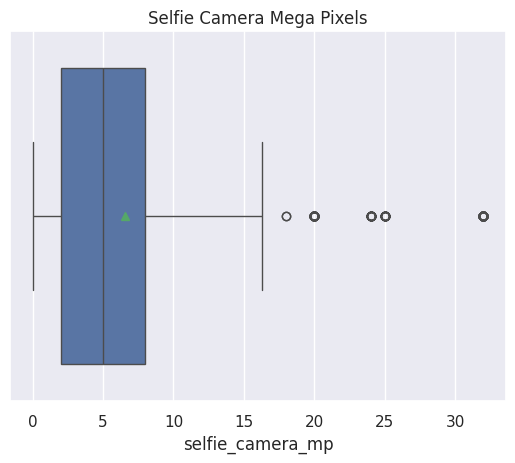

In [ ]:
#visualize selfie camera mp
sns.histplot(data=df4, x= 'selfie_camera_mp', kde=True)
plt.title('Selfie Camera Mega Pixels')
plt.show()
sns.boxplot(data=df4, x= 'selfie_camera_mp', showmeans=True)
plt.title('Selfie Camera Mega Pixels')
plt.show()

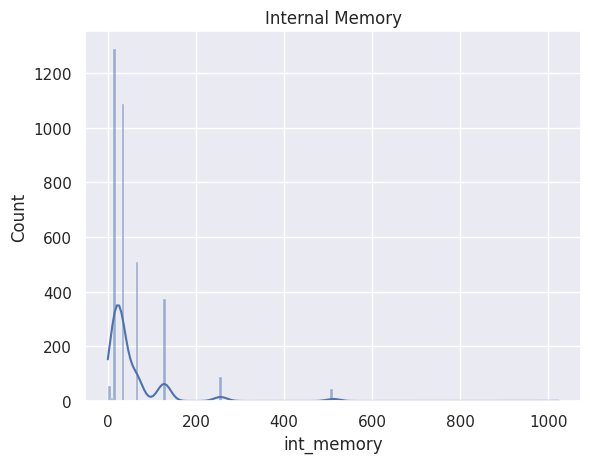

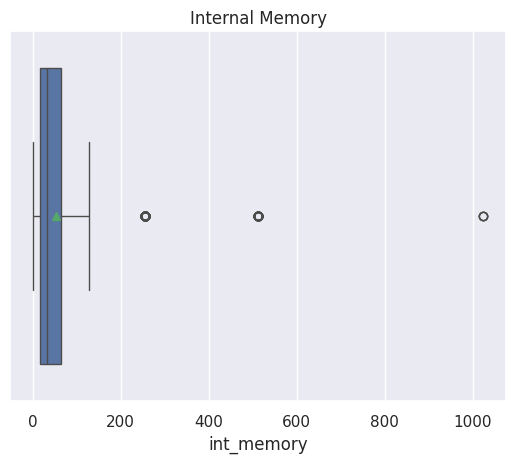

In [ ]:
#visualize internal memory
sns.histplot(data=df4, x= 'int_memory', kde=True)
plt.title('Internal Memory')
plt.show()
sns.boxplot(data=df4, x= 'int_memory', showmeans=True)
plt.title('Internal Memory')
plt.show()

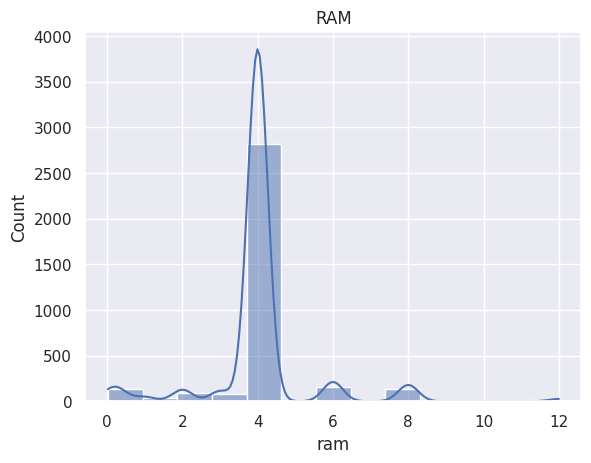

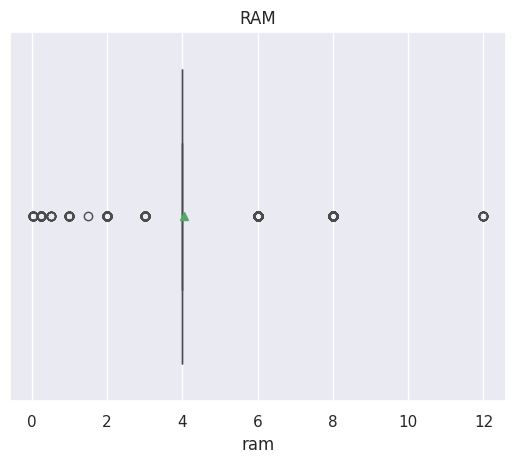

In [ ]:
#visualize RAM
sns.histplot(data=df4, x= 'ram', kde=True)
plt.title('RAM')
plt.show()
sns.boxplot(data=df4, x= 'ram', showmeans=True)
plt.title('RAM')
plt.show()

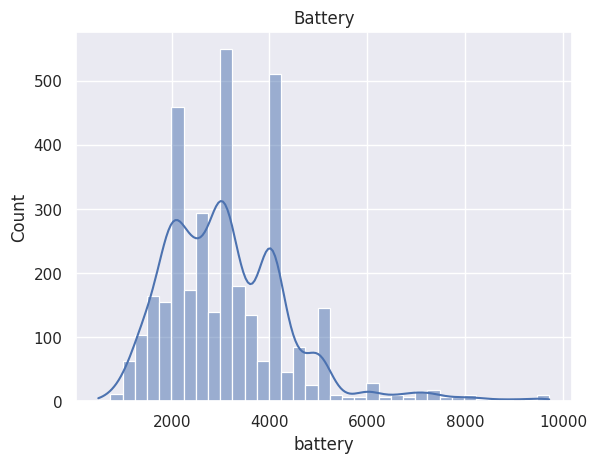

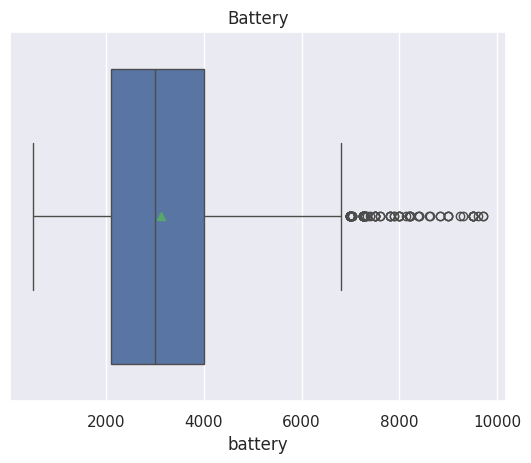

In [ ]:
#visualize Battery
sns.histplot(data=df4, x= 'battery', kde=True)
plt.title('Battery')
plt.show()
sns.boxplot(data=df4, x= 'battery', showmeans=True)
plt.title('Battery')
plt.show()

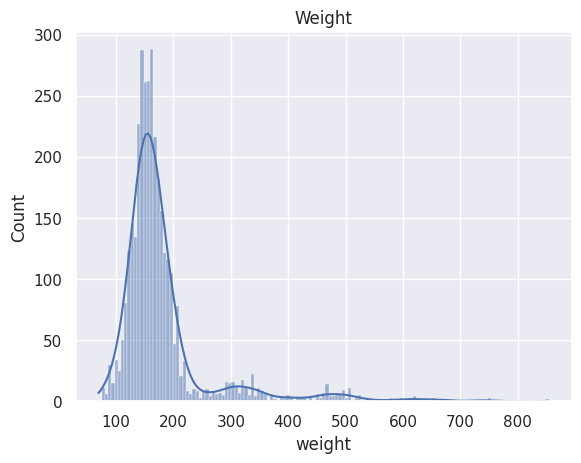

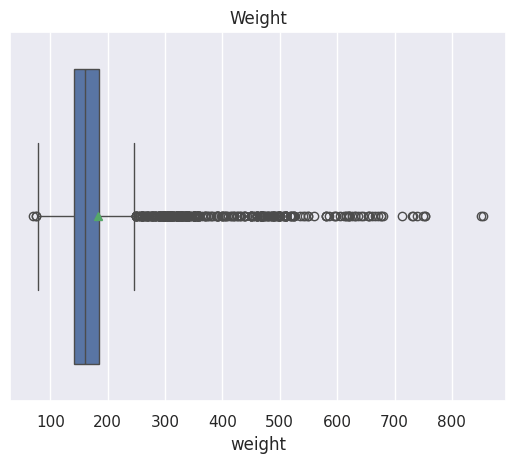

In [ ]:
#visualize weight
sns.histplot(data=df4, x= 'weight', kde=True)
plt.title('Weight')
plt.show()
sns.boxplot(data=df4, x= 'weight', showmeans=True)
plt.title('Weight')
plt.show()

- After imputing the missing values in each of the above variables we can observe similar distributions, which makes sense since we imputed with the median values.

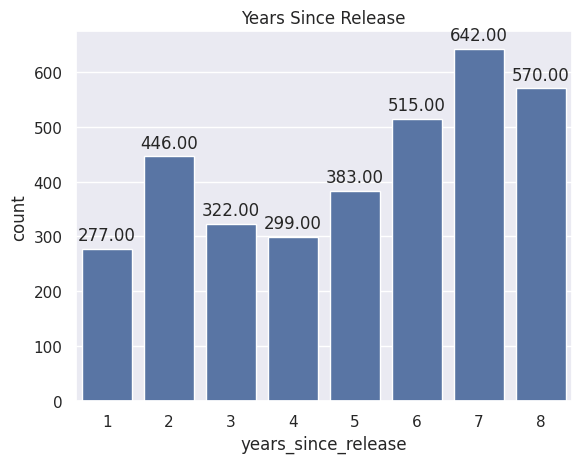

In [ ]:
#visualize the engineered feature, years_since_release
years_since_release_plot = sns.countplot(data=df4, x='years_since_release')
plt.title('Years Since Release')
for p in years_since_release_plot.patches:
  years_since_release_plot.annotate(format(p.get_height(), '.2f'), (p.get_x() + p.get_width() / 2., p.get_height()),  ha = 'center', va = 'center', xytext = (0, 10), textcoords = 'offset points')
plt.show()


- The distribution of years since release is a mirrored distibution to release year

- The only difference is since its mirrored the distribution is left skewed instead of right skewed which was observed in release year visualization.

In [ ]:
#create a variable for heatmap including numerical columns
n_cols2 = df4.select_dtypes(include = np.number).columns.to_list()
n_cols2

['screen_size',
 'main_camera_mp',
 'selfie_camera_mp',
 'int_memory',
 'ram',
 'battery',
 'weight',
 'days_used',
 'normalized_used_price',
 'normalized_new_price',
 'years_since_release']

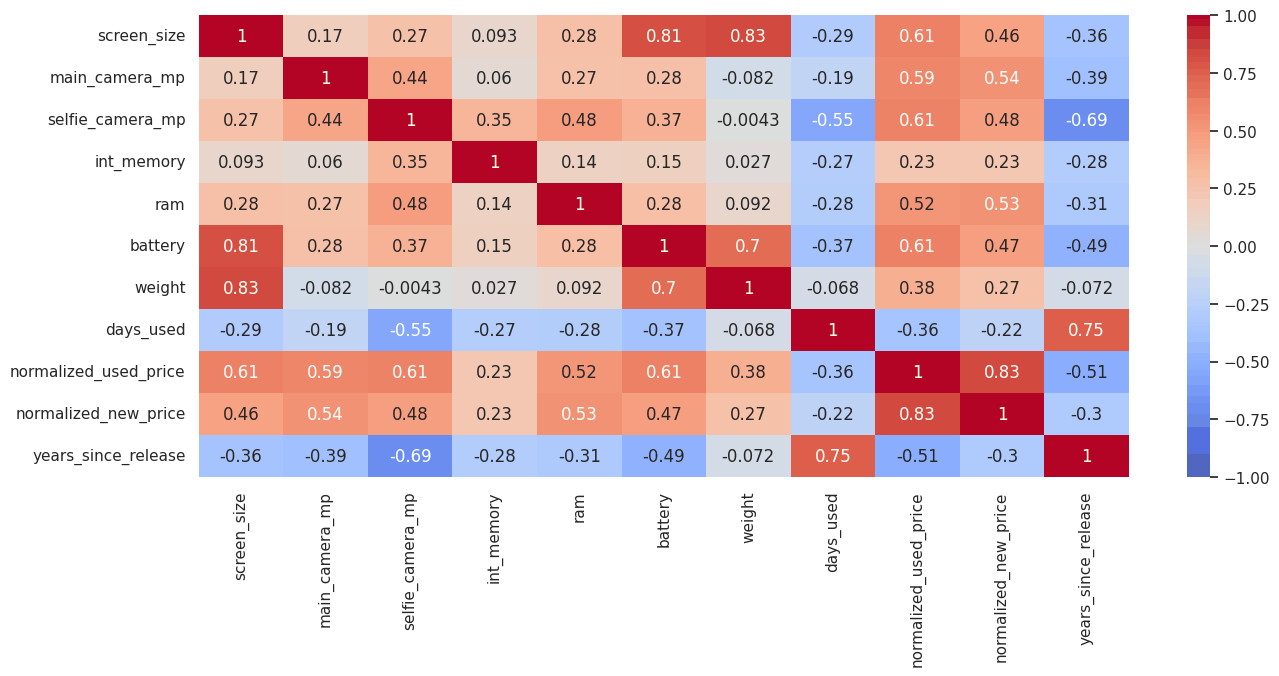

In [ ]:
#visualize correlations between numerical variables
plt.figure(figsize=(15,6))
sns.heatmap(df4[n_cols2].corr(), annot = True, vmin = -1 , vmax = 1 , cmap = 'coolwarm')
plt.show()

- After treating missing values and outliers and feature engineering, we can see marginal shifts in correlation.

- The engineered feature years_since_release is negatively correlated with normailized used price (-.51) which makes sense since the distribution years since release was inverse to the feature release_year from which it was engineered.

##Data Preparation for Modeling

In [ ]:
#set the independent variables
X = df4.drop('normalized_used_price', axis=1)
#set the dependent variable
y = df4['normalized_used_price']

print(X.head())
print( "\n")
print('dependent variable\n', y.head())

  brand_name       os  screen_size   4g   5g  main_camera_mp  \
0      Honor  Android        14.50  yes   no            13.0   
1      Honor  Android        17.30  yes  yes            13.0   
2      Honor  Android        16.69  yes  yes            13.0   
3      Honor  Android        25.50  yes  yes            13.0   
4      Honor  Android        15.32  yes   no            13.0   

   selfie_camera_mp  int_memory  ram  battery  weight  days_used  \
0               5.0        64.0  3.0   3020.0   146.0        127   
1              16.0       128.0  8.0   4300.0   213.0        325   
2               8.0       128.0  8.0   4200.0   213.0        162   
3               8.0        64.0  6.0   7250.0   480.0        345   
4               8.0        64.0  3.0   5000.0   185.0        293   

   normalized_new_price  years_since_release  
0              4.715100                    1  
1              5.519018                    1  
2              5.884631                    1  
3              5.6

In [ ]:
#Check to see that Y variable was set correctly
print(df3['normalized_used_price'].head())

0    4.307572
1    5.162097
2    5.111084
3    5.135387
4    4.389995
Name: normalized_used_price, dtype: float64


In [ ]:
#add the intercept data
X = sm.add_constant(X)

In [ ]:
#Pull the categorical variables back up to see which columns need to be converted to dummy variables
df4.describe(include= 'object').T

,count,unique,top,freq
brand_name,3454,34,Others,502
os,3454,4,Android,3214
4g,3454,2,yes,2335
5g,3454,2,no,3302


In [ ]:
#create dummies for mutually exclusive categorical variables
X = pd.get_dummies(X,
               columns= X.select_dtypes(include=['object', 'category']).columns.tolist(),
                   drop_first= True )
X.head()

,const,screen_size,main_camera_mp,selfie_camera_mp,int_memory,ram,battery,weight,days_used,normalized_new_price,...,brand_name_Spice,brand_name_Vivo,brand_name_XOLO,brand_name_Xiaomi,brand_name_ZTE,os_Others,os_Windows,os_iOS,4g_yes,5g_yes
0,1.0,14.50,13.0,5.0,64.0,3.0,3020.0,146.0,127,4.715100,...,0,0,0,0,0,0,0,0,1,0
1,1.0,17.30,13.0,16.0,128.0,8.0,4300.0,213.0,325,5.519018,...,0,0,0,0,0,0,0,0,1,1
2,1.0,16.69,13.0,8.0,128.0,8.0,4200.0,213.0,162,5.884631,...,0,0,0,0,0,0,0,0,1,1
3,1.0,25.50,13.0,8.0,64.0,6.0,7250.0,480.0,345,5.630961,...,0,0,0,0,0,0,0,0,1,1
4,1.0,15.32,13.0,8.0,64.0,3.0,5000.0,185.0,293,4.947837,...,0,0,0,0,0,0,0,0,1,0


####Splt train and test data

In [ ]:
#Split data into train and test using a 70 : 30 Split
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=1
)
# Check to see if the split worked correctly
print('X train shape', x_train.shape)
print('X test shape', x_test.shape)
print('y train shape' , y_train.shape)
print('y test shape ' , y_test.shape)

X train shape (2417, 49)
X test shape (1037, 49)
y train shape (2417,)
y test shape  (1037,)


- The training data is composed of 2417 rows
- The test data is comosed of 1037 rows

## Model Building - Linear Regression

In [ ]:
#Create the training model
olsmodel = sm.OLS(y_train, x_train).fit()


In [ ]:
#print the summary of the model
print(olsmodel.summary())

                              OLS Regression Results                             
Dep. Variable:     normalized_used_price   R-squared:                       0.845
Model:                               OLS   Adj. R-squared:                  0.842
Method:                    Least Squares   F-statistic:                     268.8
Date:                   Sun, 11 Feb 2024   Prob (F-statistic):               0.00
Time:                           01:06:41   Log-Likelihood:                 124.34
No. Observations:                   2417   AIC:                            -150.7
Df Residuals:                       2368   BIC:                             133.0
Df Model:                             48                                         
Covariance Type:               nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------


- The R-Squared value tells us that our model can explain 84.5% of the variance in the training data
- The Adjusted R-Squared for the model is good, having a value of .842
- The constant coefficient for our model is 1.3168
- We note the presence of high p-values which will need treatment

## Model Performance Check

### Metrics for performance Check

- Metric functions already defined in sklearn: RMSE, MAE and $R^2$
- Functions needing to be defined: MAPE and adjusted $R^2$
- Let's define a function to use which includes the sklearn metrics and the metrics we are defining to be called all at once.

In [ ]:
#function for adjusted R^2

def adj_r2_score (predictors, targets, predictions):
  r2 = r2_score(targets, predictions)
  n = predictors.shape[0]
  k = predictors.shape[1]
  return 1 - ((1 - r2) * (n - 1) / (n - k - 1))

#function for MAPE

def MAPE_score (targets, predictions):
  return np.mean(np.abs(targets-predictions) / targets) * 100

#function to call all metrics for performance check of the model
def model_performance_regression (model, predictors, target):
  """
  model: regressor
  predictors: independent variable
  target: dependent variable
  """

  #predict using the independent variable
  pred = model.predict(predictors)

  r2 = r2_score(target, pred) #compute R^2
  adjr2 = adj_r2_score(predictors, target, pred) #compute adjusted R^2
  rmse = np.sqrt(mean_squared_error(target, pred)) #compute RMSE
  mae = mean_absolute_error(target, pred) #compute MAE
  mape = MAPE_score(target, pred) #compute MAPE

  #create a dataframe for the preformance metrics
  df_perf = pd.DataFrame({
      'RMSE': rmse ,
      'MAE': mae ,
      'R-Squared' : r2,
      'Adj. R-Squared' : adjr2 ,
      'MAPE': mape
  },
                         index=[0])

  return df_perf



In [ ]:
#checking model performance on train set
print("Training Performance\n")
olsmodel_train_perf = model_performance_regression(olsmodel, x_train, y_train)
olsmodel_train_perf

Training Performance



,RMSE,MAE,R-Squared,Adj. R-Squared,MAPE
0,0.229837,0.180316,0.844949,0.841739,4.327676


In [ ]:
#check model performance on test set
print("Test Performance\n")
olsmodel_test_performance = model_performance_regression(olsmodel, x_test, y_test)
olsmodel_test_performance

Test Performance



,RMSE,MAE,R-Squared,Adj. R-Squared,MAPE
0,0.239486,0.185359,0.840984,0.83309,4.513415


Observations

 - The $R^2$ is .845, so the model is not underfitting
 - The train and test RMSE and MAE are comparable, so the model is not overfitting either.
 - The MAE suggests the model can predict normalized used price with a mean error of .18 on the test data
 - MAPE of 4.51 on the rest data means that we are able to predict within 4.51% of the normalized used price.

## Checking Linear Regression Assumptions

- In order to make statistical inferences from a linear regression model, it is important to ensure that the assumptions of linear regression are satisfied.

Linear Regression Assumptions
1. No Multicollinearity
2. Linearity of Variables
3. Independence of Error Terms
4. Normality of Error Terms
5. No Heteroscedasticity

### Test for Multicolinearity

- Variance Inflation Factor
  - This test will compute the VIF which tests for multicollinearity
  General Rule of thumb:

    - If VIF is 1 then there is no correlation between the $k$th predictor and the remaining predictor variables.
    - If VIF exceeds 5 or is close to exceeding 5, we say there is moderate multicollinearity.
    - If VIF is 10 or exceeding 10, it shows signs of high multicollinearity.
  - We will address columns showing strong (VIF > 10) and moderate (VIF > 5) multicollinearity

In [ ]:
#start by defining VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor

def checking_vif(predictors):
  vif = pd.DataFrame()
  vif['feature'] = predictors.columns

  #calculating VIF for each feature
  vif['VIF'] = [
      variance_inflation_factor(predictors.values, i)
      for i in range(len(predictors.columns))
      ]
  return vif

In [ ]:
checking_vif(x_train)

,feature,VIF
0,const,227.765513
1,screen_size,7.683304
2,main_camera_mp,2.291401
3,selfie_camera_mp,2.823876
4,int_memory,1.448377
5,ram,2.288816
6,battery,4.081824
7,weight,6.396232
8,days_used,2.658548
9,normalized_new_price,3.149464


- There are two columns with VIF above 10 which indicates the presenece of strong multicollinearity
- We'll address these before looking to see which columns have a multicollinearity above 5

In [ ]:
#define a function to assist with dropping columns with strong multicollinearity
def treating_multicollinearity (predictors, target, high_vif_columns):
  """
  Used to check the effect of dropping the columns showing strong multicollinearity
  in reference to model performance; namely RMSE and Adjusted R-Squared

  predictors: Independent variables
  target: dependent variable
  high_vif_columns: columns having high VIF

  """
  #Create lists to store Adjusted R-Squared and RMSE values
  adj_r2 = []
  rmse = []

  #build ols models by dropping one of the high VIF columns at a time
  for cols in high_vif_columns:
    #defining new train set
    train = predictors.loc[:, ~predictors.columns.str.startswith(cols)]

    #create the model
    olsmodel = sm.OLS(target, train).fit()

    #adding adjusted R-Squared and RMSE to the lists created earlier
    adj_r2.append(olsmodel.rsquared_adj)
    rmse.append(np.sqrt(olsmodel.mse_resid))

  #create a dataframe for results
  temp = pd.DataFrame(
        {
            'col': high_vif_columns ,
            'Adjusted R-Squared after dropping col': adj_r2,
            'RMSE after dropping col' : rmse,
            }
    ).sort_values(by='Adjusted R-Squared after dropping col', ascending = False)

  temp.reset_index(drop=True, inplace = True)

  return temp


Removing Multicollinearty
- We will drop every column one by one with VIF scores greater than 5
- Before dropping we will check to see if dropping a column will have a drastic reduction in adjusted r squared.
- We will conduct another VIF check after dropping each variable to reassess the targets and needs for removal of variables
- Once all remaining VIF's < 5 we can continue on.

In [ ]:
#Check the e
col_list = ['brand_name_Apple', 'os_iOS']

res_vif = treating_multicollinearity(x_train, y_train, col_list)
res_vif

,col,Adjusted R-Squared after dropping col,RMSE after dropping col
0,brand_name_Apple,0.841873,0.232154
1,os_iOS,0.841859,0.232164


- The difference between dropping each is marginal, so we'll go with brand_name_Apple as the first drop since the VIF was higher

In [ ]:
#dropping brand name apple off both the train and test set
col_to_drop = 'brand_name_Apple'
x_train2 = x_train.drop('brand_name_Apple' ,axis=1)
x_test2 = x_test.drop('brand_name_Apple', axis=1)

# Check VIF after dropping
vif = checking_vif(x_train2)
print('VIF after dropping', col_to_drop)
vif.sort_values(by='VIF' , ascending= False)


VIF after dropping brand_name_Apple


,feature,VIF
0,const,227.327730
33,brand_name_Others,9.074045
1,screen_size,7.649683
36,brand_name_Samsung,6.991508
7,weight,6.393489
20,brand_name_Huawei,5.582398
10,years_since_release,4.920340
23,brand_name_LG,4.565678
25,brand_name_Lenovo,4.291875
6,battery,4.079765


- OS_ios is now 1.9 and the strong multicollinearity on this column has been fixed

- Now we'll look at the columns with a VIF greater than 5




In [ ]:
#recheck for VIF Values
col_list2 = vif.loc[vif['VIF'] > 5]
col_list2

,feature,VIF
0,const,227.327730
1,screen_size,7.649683
7,weight,6.393489
20,brand_name_Huawei,5.582398
33,brand_name_Others,9.074045
36,brand_name_Samsung,6.991508


In [ ]:
#Check effect on model when dropping each variable
res_vif2 = treating_multicollinearity(x_train2, y_train , col_list2['feature'])
res_vif2

,col,Adjusted R-Squared after dropping col,RMSE after dropping col
0,const,0.996825,0.248294
1,brand_name_Huawei,0.841939,0.232105
2,brand_name_Others,0.841937,0.232107
3,brand_name_Samsung,0.841902,0.232132
4,screen_size,0.838476,0.234634
5,weight,0.838209,0.234828


- The difference in Adjusted R Squared and RMSE after dropping each column is marginal, so we'll address brand_name_Others	first and check the VIF again

In [ ]:
#dropping brand name Others off both the train and test set
col_to_drop2 = 'brand_name_Others'
x_train3 = x_train2.drop('brand_name_Others' ,axis=1)
x_test3 = x_test2.drop('brand_name_Others', axis=1)

# Check VIF after dropping brand name Others
vif = checking_vif(x_train3)
print('VIF after dropping', col_to_drop2)
vif.sort_values(by='VIF' , ascending= False)

VIF after dropping brand_name_Others


,feature,VIF
0,const,150.458269
1,screen_size,7.576238
7,weight,6.367694
10,years_since_release,4.919817
6,battery,4.079541
9,normalized_new_price,3.131197
3,selfie_camera_mp,2.800820
8,days_used,2.657790
45,4g_yes,2.464325
2,main_camera_mp,2.289388


In [ ]:
#checking VIF values over 5 still remaining
col_list3 = vif.loc[vif['VIF'] > 5]
col_list3

res_vif3 = treating_multicollinearity(x_train3, y_train , col_list3['feature'])
res_vif3

,col,Adjusted R-Squared after dropping col,RMSE after dropping col
0,const,0.996629,0.255848
1,screen_size,0.838490,0.234624
2,weight,0.838272,0.234782


- Screen size has a lesser effect on the overall $R^2$, however it does still contain moderate multicollinearity with its VIF being over 7.

- It can be argued whether or not to drop screen size and weight due to multicollinearity.

- In the case of this model, we will be dropping screen_size, however the model could be developed without treating screen_size or weight and will likely still perform rather well.

In [ ]:
#dropping screen size off both the train and test set
col_to_drop3 = 'screen_size'
x_train4 = x_train3.drop('screen_size' ,axis=1)
x_test4 = x_test3.drop('screen_size', axis=1)

# Check VIF after dropping screen size
vif = checking_vif(x_train4)
print('VIF after dropping', col_to_drop3)
vif.sort_values(by='VIF' , ascending= False)

VIF after dropping screen_size


,feature,VIF
0,const,132.705635
9,years_since_release,4.741454
5,battery,3.832859
8,normalized_new_price,3.081417
6,weight,2.988943
2,selfie_camera_mp,2.798471
7,days_used,2.646472
44,4g_yes,2.463141
1,main_camera_mp,2.286587
4,ram,2.276605


All Multicollinearity has been treated

In [ ]:
#creating a new model which has been treated for multicollinearity
olsmod1 = sm.OLS(y_train, x_train4).fit()
print(olsmod1.summary())

                              OLS Regression Results                             
Dep. Variable:     normalized_used_price   R-squared:                       0.841
Model:                               OLS   Adj. R-squared:                  0.838
Method:                    Least Squares   F-statistic:                     279.7
Date:                   Sun, 11 Feb 2024   Prob (F-statistic):               0.00
Time:                           01:07:29   Log-Likelihood:                 97.746
No. Observations:                   2417   AIC:                            -103.5
Df Residuals:                       2371   BIC:                             162.9
Df Model:                             45                                         
Covariance Type:               nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------


Observations

- We can see after removing multicollinearity our R-sqaured and Adjusted R-squared dropped but only slightly
  - $R^2$ went from .845 to .841
  - Adj. $R^2$ went from .842 to .838
- The dropped columns did not have much of an effect on the overall performance of the model

#### Dealing with high P-Values

- Now that we've treated multicollinearity we can now address the p-values of predictor variables to check their significance.

Null Hypothesis: Independent feature is not significant

Alternative Hypothesis: Independent feature is that it is significant

- If the feature is not deemed significant (p-value > .05) then it can be removed from the model.


In [ ]:
#create a copy of training independent variables set
predictors= x_train4.copy()
cols = predictors.columns.tolist()

#set a max p-value
max_p_value = 1

while len(cols)> 0:
  #define the training set
  x_train_aux = predictors[cols]

  #fitting the model
  model = sm.OLS(y_train, x_train_aux).fit()

  #get the p-values and the max p-value
  p_values= model.pvalues
  max_p_value = max(p_values)

  #name of the variables with maximum p-value
  feature_with_p_max = p_values.idxmax()

  if max_p_value > .05:
    cols.remove(feature_with_p_max)
  else:
    break
selected_features= cols
print(selected_features)

['const', 'main_camera_mp', 'selfie_camera_mp', 'ram', 'weight', 'normalized_new_price', 'years_since_release', 'brand_name_Karbonn', 'brand_name_Lenovo', 'brand_name_Nokia', 'brand_name_Xiaomi', 'os_Others', '4g_yes', '5g_yes']


In [ ]:
#setting the independent variables for  x_train and x_test
x_train5 = x_train4[selected_features]
x_test5 = x_test4[selected_features]

In [ ]:
#Creating an updated model which has been treated for high p-value variables
olsmod2 = sm.OLS(y_train, x_train5).fit()
print(olsmod2.summary())

                              OLS Regression Results                             
Dep. Variable:     normalized_used_price   R-squared:                       0.839
Model:                               OLS   Adj. R-squared:                  0.838
Method:                    Least Squares   F-statistic:                     965.2
Date:                   Sun, 11 Feb 2024   Prob (F-statistic):               0.00
Time:                           01:10:02   Log-Likelihood:                 80.857
No. Observations:                   2417   AIC:                            -133.7
Df Residuals:                       2403   BIC:                            -52.65
Df Model:                             13                                         
Covariance Type:               nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
co

In [ ]:
#check to see how the performance is looking between train and test before moving forward
#checking model performance on train set
print("Training Performance\n")
olsmodel_train_perf = model_performance_regression(olsmod2, x_train5, y_train)
olsmodel_train_perf

Training Performance



,RMSE,MAE,R-Squared,Adj. R-Squared,MAPE
0,0.23401,0.18301,0.839268,0.838331,4.398555


In [ ]:
#testing model performance on test set
print("Test Performance\n")
olsmodel_test_perf = model_performance_regression(olsmod2, x_test5, y_test)
olsmodel_test_perf

Test Performance



,RMSE,MAE,R-Squared,Adj. R-Squared,MAPE
0,0.242115,0.18802,0.837474,0.835248,4.579771


- Still looking good on the model performance between train and test sets
- Treating the p-values had a marginal effect of R-squared and adjusted R-squared. The R-squared is still able to explain 83.7% of the variance in the training and 83.5% in the test set.
- RMSE and MAE are still comparable between train and test sets, so we are not overfitting.
- It is safe to proceed with x_train5 and olsmod2 since the treatments on multicollinearity and significance are still comparable to pre-treatment x_train and olsmodel

### Test for Linearity and Independence


- We will test for linearity and independence by visualizing a plot showing residulas vs fitted values
- If there is no apparent pattern in the plot we can say the model is linear and the residuals are independent.
- A pattern in the plot will signal non-linearity in the model and the residuals not being independent

In [ ]:
#create a data frame for actual, fitted and residual values

df_pred = pd.DataFrame()

df_pred['actual_values'] = y_train
df_pred['fitted_values'] = olsmod2.fittedvalues
df_pred['residuals'] = olsmod2.resid
#Check the new data frame
df_pred.head()

,actual_values,fitted_values,residuals
3026,4.087488,3.860330,0.227158
1525,4.448399,4.641121,-0.192722
1128,4.315353,4.280485,0.034868
3003,4.282068,4.182338,0.099730
2907,4.456438,4.484614,-0.028176


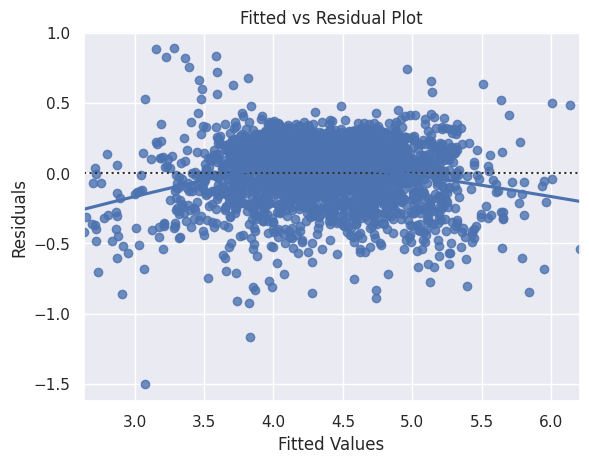

In [ ]:
#plot the fitted values vs residuals

sns.residplot(data=df_pred, x='fitted_values', y='residuals', lowess=True)

plt.title('Fitted vs Residual Plot')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.show()

- There's no apparent pattern in the scatter plot between fitted values and residuals
- We can assume there is linearity and independence of residuals between the variables

### Test for Normality

1. Visual Test - Histogram
  - Does the histogram take on the appearance of a bell-shaped curve, signaling a normal distribution
2. Q-Q plot of residuals
  - How well does the plot follow the 45 degree line
3. Shapiro-Wilk Test
  - p-value > .05 shows a normal distribution

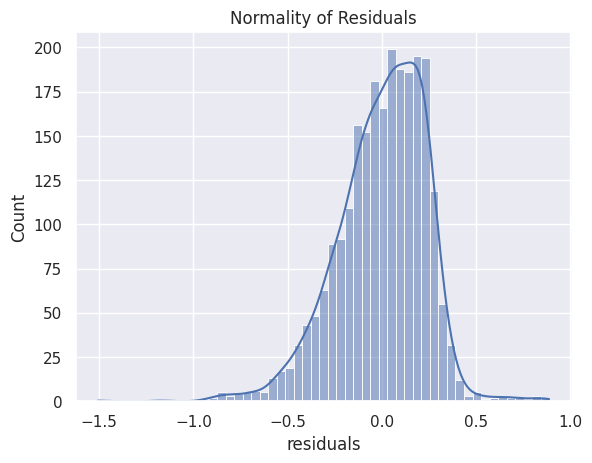

In [ ]:
#visualize a historgram of the residuals to check for a normal distribution
sns.histplot(data=df_pred, x='residuals', kde=True)
plt.title('Normality of Residuals')
plt.show()

- The plot resembles a generally normal distribution with a curve somewhat resembling a bellshape

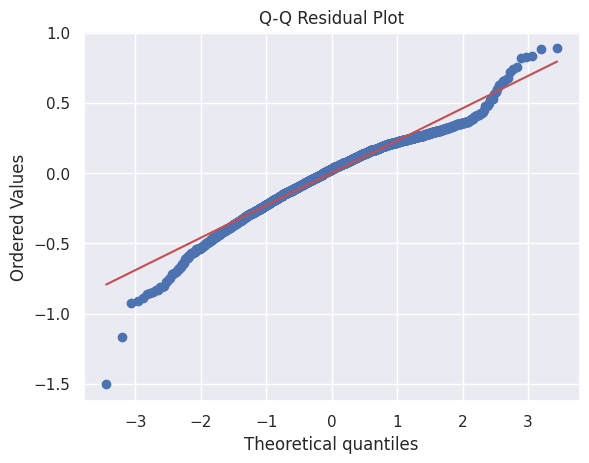

In [ ]:
#Q-Q plot
import pylab
import scipy.stats as stats

stats.probplot(df_pred['residuals'], dist = 'norm', plot=pylab)
plt.title('Q-Q Residual Plot')
plt.show()

- While there is some deviance from the straight line in the plot. Most of the plot follows the line other than some variance at the head and tail of the plot.
- There is a presenece of some non-linearity but more of the plot points towards normaility within a linear model.

In [ ]:
#Shapiro-Wilk's Test
stats.shapiro(df_pred['residuals'])

ShapiroResult(statistic=0.9683110117912292, pvalue=1.1352272619449774e-22)

- Since p-value < 0.05, we must reject the null hypothesis stating the distribution is normal.
- According to this test, in the strictest sense, the residuals are not normally distributed.
- However, visually from the histogram and the Q-Q test we can approximate the distribution as being close to normal.

### Test for Homoscedasticity



- We will be using the goldfeldquandt test.
- If p-value > .05 we can conclude homoscedasticity in the residuals

In [ ]:
import statsmodels.stats.api as sms
from statsmodels.compat import lzip

name = ['F Statistic', 'p-value']
test= sms.het_goldfeldquandt(df_pred['residuals'], x_train5)
lzip(name, test)

[('F Statistic', 1.0191626468802135), ('p-value', 0.37147480492802887)]

Since the p-value is > .05, we fail to reject the null hypothesis and can say the residuals are homoscedastic

## Final Model

In [ ]:
#Set x_train and x_test variables for the final model
x_train_final = x_train5.copy()
x_test_final = x_test5.copy()

In [ ]:
#Create the final model
olsmodel_final = sm.OLS(y_train, x_train_final).fit()
print(olsmodel_final.summary())

                              OLS Regression Results                             
Dep. Variable:     normalized_used_price   R-squared:                       0.839
Model:                               OLS   Adj. R-squared:                  0.838
Method:                    Least Squares   F-statistic:                     965.2
Date:                   Wed, 07 Feb 2024   Prob (F-statistic):               0.00
Time:                           05:04:04   Log-Likelihood:                 80.857
No. Observations:                   2417   AIC:                            -133.7
Df Residuals:                       2403   BIC:                            -52.65
Df Model:                             13                                         
Covariance Type:               nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
co

In [ ]:
#training performance check
print("Training Performance\n")
olsmodel_final_train_perf = model_performance_regression(olsmodel_final, x_train_final, y_train)
olsmodel_final_train_perf

Training Performance



,RMSE,MAE,R-Squared,Adj. R-Squared,MAPE
0,0.23401,0.18301,0.839268,0.838331,4.398555


In [ ]:
#test performance check
print("Test Performance\n")
olsmodel_final_test_perf = model_performance_regression(olsmodel_final, x_test_final, y_test)
olsmodel_final_test_perf

Test Performance



,RMSE,MAE,R-Squared,Adj. R-Squared,MAPE
0,0.242115,0.18802,0.837474,0.835248,4.579771


In [ ]:
#check predictions vs actual on test data
pred= olsmodel_final.predict(x_test_final)

df_pred_test = pd.DataFrame({'actual': y_test , 'predicted': pred})
df_pred_test.sample(10, random_state=1)

,actual,predicted
1995,4.566741,4.375834
2341,3.696103,3.996268
1913,3.592093,3.638329
688,4.306495,4.090478
650,4.522115,5.178461
2291,4.259294,4.386189
40,4.997685,5.440825
1884,3.875359,4.044567
2538,4.206631,4.060787
45,5.380450,5.216557


Observations

- The final model is able to explain ~84% of the variance in the data so it is not underfitting
- The RMSE and MAE between test are low and comparable, so there is no overfitting present in the model
- The MAPE on the test data shows the ability to predict within 4.58% of the normalized used price of devies.
- We are able to conclude the model olsmodel_final is good for both prediction and inference purposes.

## Actionable Insights and Recommendations

- The model is able to explain ~ 84% of the variation in the data and with 4.58% of the normalized used price on the test data.
  - The model can be assumed to be good both for prediction and inference purposed

- If all devices attributes were 0, the constant coefficient will yield a normalized used price of 1.51 Euros

- If the mega pixels of the main camera were to increase by 1 unit, then the normalized used price would increase by .0213 units, all other variables held constant

- If the mega pixels of the selfie camera were to increase by 1 unit, the the normalized used price would increase by .0143 units, all other variables held constant

- The megapixels of the main camera is has a larger positive influence on the normalized used price, than selfie camera megapixels. When looking to acquire inventory the focus should primarily be on the main camera quality rather than the selfie camera quality.

- If the RAM of the devices were to increase by 1 unit, the normalized used price would increase by .0227 Euros

- For every unit increase in the normalized new price of the device, the normalized used price of the device would increase by .43 Euros, all values held constant.

- For every unit increase in years since release, the used price of the device will decrease by .4342

- Having an non-common OS present in the 'Others' variable have a negative influence on normalized used price, -0.142 Euros. Operating systems which are more recognizable and popular, not falling into the 'Others' category are more desirable and will have a higher normalized used price (all other variables being equal). This makes sense because of the familiarity and desirability of well recognized and established operating systems. It is recommended to stock devices with the Android OS, when looking to improve the profitability of individual devices.

- The normalized new price of the device has the largest positive influence on the normalized used price.

- In 2021 having a 5g enabled device will reduce the value of the device by    -0.0645 Euros. This is likely due to the limited accessibility of the newly released 5g network. In 2021 it would be better to hold inventory without 5g capability, however this will likely shift with expansion and accesibility of the 5g network. Once this occurs the model will need to be adjusted.

- Karbonn hold more inherent value than other brands, contributing to .1223 Euros if the device is Karbonn branded.

- Its interesting to see that days used was removed from the model. Rather than the duration of use for the specific device, the years since release, is a more useful factor determining the normalized used price of the device. Unlike a car which decreases with mileage, the value of a used device seems to be in the age of its internal technology rather then the 'wear and tear' from the use of the specific device. Of course visual quality and wear and tear will effect value, but if the devices visually look the same and perform the same. A device used for 1 year and one used for 2 years could hold the same normalized_used_price given the same features and years since release.




___